# Домашнее задание №1 "Пять рекомендательных моделей на KuaiRec"

**ФИО:** Акопова Елена Николаевна.

**Задача:** реализовать 5 методов рекомендательных систем и оценить их работу на датасете KuaiRec, предлагая пользователю top-10 видео. В ходе работы реализованы UserKNN, iALS,
EASE, FM с категориями и iALS с собственным целевым сигналом. Основными метриками выбраны NDCG@10 и Recall@10, для воспроизводимости экспериментов установлен random_seed — 42.


### Данные и запуск

Скачайте big_matrix.csv, small_matrix.csv, item_categories.csv, user_features.csv,
item_daily_features.csv и social_network.csv из
[официальной папки KuaiRec](https://drive.google.com/drive/folders/1bAm07YnKRKB6SVHB8Mqz6v6W8ppLaJwB).
Описание полей и отбора: [DATA.md](DATA.md). CSV положите в data/ в корне
репозитория либо задайте абсолютный путь через KUAIREC_DATA_DIR. В Git данные не входят.

Из корня репозитория, Python 3.11:

~~~bash
python3.11 -m venv .venv
source .venv/bin/activate
python -m pip install -r hw1/requirements.txt
cd hw1
../.venv/bin/python -m notebook experiments.ipynb
~~~

Выберите ядро окружения, перезапустите его и выполните ячейки сверху вниз.
В Colab скопируйте содержимое hw1/ целиком в рабочую папку и укажите путь к CSV
на подключённом Google Drive. Полный перебор — 193 конфигурации и один контрольный
CustomALS; сумма времени сохранённых конфигураций — около 74 минут без EDA
и финальной оценки. Время зависит от оборудования и BLAS.


Таблицы validation-перебора, выбранные параметры, обученные модели и результаты
оценки хранятся в памяти текущего ядра. Графики и таблицы отображаются в ноутбуке;
отдельные файлы с результатами не читаются и не создаются.
После перезапуска ядра выполните все ячейки заново.

## Установка random_seed

In [2]:
import os
import random
import numpy as np

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

## 1. Загрузка и описание данных

Датасет **KuaiRec** — это открытый набор реальных данных, собранных из логов китайской платформы для обмена короткими видео Kuaishou. Он содержит информацию о взаимодействиях пользователей с видео, а также дополнительные характеристики пользователей и объектов.

Основу датасета составляют две таблицы взаимодействий — *small_matrix.csv* и *big_matrix.csv* - это матрицы с различной степенью заполненности.


*   **small_matrix** содержит 4 676 570 взаимодействий 1 411 пользователей с 3327 видео, заполненность *99,6%*

*   **big_matrix** содержит 12 530 806 взаимодействий 7 176 пользователей с 10 728 видео при заполненности около *16,3%*

Каждая запись описывает взаимодействие пользователя с определённым видео. Для каждой пары пользователя и видео доступны идентификаторы `user_id` и `video_id`, длительность просмотра `play_duration`, длительность видео `video_duration` и временная метка взаимодействия `timestamp`. На основе этих данных рассчитывается показатель **`watch_ratio`**, представляющий собой отношение времени просмотра к продолжительности видео. Он используется в качестве количественного сигнала предпочтения: более высокие значения могут свидетельствовать о большем интересе пользователя к контенту, хотя этот показатель не является прямой оценкой удовлетворенности.

Помимо пользовательских взаимодействий, в датасете представлены дополнительные признаки. Файл user_features.csv содержит характеристики пользователей, item_categories.csv — категории видео, а item_daily_features.csv — ежедневную статистику и характеристики объектов. Файл social_network.csv описывает связи между пользователями. Эти сведения позволяют использовать не только историю взаимодействий, но и метапризнаки пользователей и видео, что особенно важно для построения факторизационной машины (FM).

В данной работе KuaiRec используется для решения задачи персонализированного ранжирования видео. Для каждого пользователя необходимо сформировать top-10 видео, которые предположительно будут ему наиболее интересны. Качество рекомендаций оценивается на отложенных взаимодействиях, которые не использовались при обучении моделей. Поскольку датасет содержит временные метки, для разделения данных на обучающую, валидационную и тестовую выборки используется временной принцип. Для обеспечения воспроизводимости фиксируется random_seed.

**Источник данных:** [KuaiRec — официальный репозиторий GitHub](https://github.com/chongminggao/KuaiRec), [страница проекта](https://kuairec.com/).



Авторы пишут:  

> *"We provide some basic statistics of the KuaiRec dataset. The description of this dataset can be referred to https://chongminggao.github.io/KuaiRec/"*

Поэтому возьмем часть реализованной ими аналитики

## 2. EDA

EDA основан на [официальном разборе KuaiRec](https://kuairec.com/Statistics_KuaiRec.html).

### Загрузка CSV

Скачайте шесть CSV по инструкции в начале ноутбука и в [DATA.md](DATA.md). Для Colab подключите Google Drive, установите зависимости и задайте KUAIREC_DATA_DIR. Рабочим каталогом должна быть папка с models/ и utils/.

In [3]:
from pathlib import Path
import os

if 'google.colab' in __import__('sys').modules:
    from google.colab import drive
    drive.mount('/content/drive')

# Путь по умолчанию — data/ в корне репозитория.
rootpath = Path(os.environ.get('KUAIREC_DATA_DIR', '../data')).expanduser().resolve()
required_files = ['big_matrix.csv', 'small_matrix.csv', 'social_network.csv',
                  'item_categories.csv', 'user_features.csv', 'item_daily_features.csv']
missing_files = [name for name in required_files if not (rootpath / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'В {rootpath} отсутствуют {missing_files}. См. DATA.md или задайте KUAIREC_DATA_DIR.')
print('Каталог CSV:', rootpath)

Каталог CSV: /workspace-SR008.fs2/enakopova/five_recsys_models/data


In [4]:
import ast
import pandas as pd

print("Loading big matrix...")
big_matrix = pd.read_csv(Path(rootpath) / 'big_matrix.csv')
print("Loading small matrix...")
small_matrix = pd.read_csv(Path(rootpath) / 'small_matrix.csv')
social_network = pd.read_csv(Path(rootpath) / 'social_network.csv')
social_network['friend_list'] = social_network.friend_list.map(ast.literal_eval)
item_categories = pd.read_csv(Path(rootpath) / 'item_categories.csv')
item_categories['feat'] = item_categories.feat.map(ast.literal_eval)
user_features = pd.read_csv(Path(rootpath) / 'user_features.csv')
item_daily_features = pd.read_csv(Path(rootpath) / 'item_daily_features.csv')
print('All data loaded.')

Loading big matrix...


Loading small matrix...


All data loaded.


### Таблицы взаимодействий и метаданные

In [4]:
big_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,0,3649,13838,10867,2020-07-05 00:08:23.438,20200705,1.593879e+09,1.273397
1,0,9598,13665,10984,2020-07-05 00:13:41.297,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,2020-07-05 00:16:06.687,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,2020-07-05 00:20:26.792,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,2020-07-05 00:43:05.128,20200705,1.593881e+09,0.078000
...,...,...,...,...,...,...,...,...
12530801,7175,1281,34618,140017,2020-09-05 15:07:10.576,20200905,1.599290e+09,0.247241
12530802,7175,3407,12619,21888,2020-09-05 15:08:45.228,20200905,1.599290e+09,0.576526
12530803,7175,10360,2407,7067,2020-09-05 19:10:29.041,20200905,1.599304e+09,0.340597
12530804,7175,10360,6455,7067,2020-09-05 19:10:36.995,20200905,1.599304e+09,0.913400


In [5]:
print(f'''{int(big_matrix['timestamp'].isna().sum())/len(big_matrix):.4f} взаимодействий без временных меток ({int(big_matrix['timestamp'].isna().sum())}/{len(big_matrix)})''')

0.0000 взаимодействий без временных меток (0/12530806)


In [6]:
print(f'''число уникальных взаимодействий по паре юзер-айтем {len(big_matrix.groupby(['user_id', 'video_id']).size())} / {len(big_matrix)}''')

число уникальных взаимодействий по паре юзер-айтем 10300969 / 12530806


Следовательно есть случаи, когда один и тот же юзер смотрел одно и то же видео, но в разные моменты времени. Для построения матрицы взаимодействия нужно придумать стратегию агрегации таких случаев: min/max/last/first/mean...

In [7]:
small_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364
...,...,...,...,...,...,...,...,...
4676565,7162,2267,11908,5467,NaN,NaN,NaN,2.178160
4676566,7162,2065,11919,6067,NaN,NaN,NaN,1.964562
4676567,7162,1296,16690,19870,NaN,NaN,NaN,0.839960
4676568,7162,4822,11862,24400,NaN,NaN,NaN,0.486148


In [8]:
small_matrix.isna().sum() / len(small_matrix) # получилось 0.0389 взаимодействий без временных меток (181992/4676570)

user_id           0.000000
video_id          0.000000
play_duration     0.000000
video_duration    0.000000
time              0.038916
date              0.038916
timestamp         0.038916
watch_ratio       0.000000
dtype: float64

In [9]:
print(f'''число уникальных взаимодействий по паре юзер-айтем {len(small_matrix.groupby(['user_id', 'video_id']).size())} (все уникальные)''')

число уникальных взаимодействий по паре юзер-айтем 4676570 (все уникальные)


In [5]:
import numpy as np
import pandas as pd


def aggregate_pairs(frame):
    """Усредняет watch_ratio пары; сохраняет последнюю timestamp и остальные поля первой строки."""
    keys = ['user_id', 'video_id']
    aggregations = {column: ('mean' if column == 'watch_ratio' else
                             'max' if column == 'timestamp' else 'first')
                    for column in frame.columns if column not in keys}
    result = frame.groupby(keys, as_index=False, sort=True).agg(aggregations)
    return result.loc[:, frame.columns]


# 1. Очищаем обе матрицы
big_df, small_df = big_matrix.dropna(
    subset=["timestamp", "user_id", "video_id", "watch_ratio"]
).copy(), small_matrix.dropna(
    subset=["timestamp", "user_id", "video_id", "watch_ratio"]
).copy()

# Невалидные и отрицательные сигналы не используются.
big_df = big_df[np.isfinite(big_df.watch_ratio) & (big_df.watch_ratio >= 0)]
small_df = small_df[np.isfinite(small_df.watch_ratio) & (small_df.watch_ratio >= 0)]

# 2. Воспроизводимо выбираем пользователей и видео по big_matrix.
# Фиксируем seed, чтобы состав выборки не менялся между запусками.

np.random.seed(SEED)
all_users = big_df["user_id"].drop_duplicates().to_numpy()
all_items = big_df["video_id"].drop_duplicates().to_numpy()

selected_users = np.random.choice(
    all_users, size=2200, replace=False
)
selected_items = np.random.choice(
    all_items, size=4700, replace=False
)

# 3. Оставляем выбранных пользователей и видео в обеих матрицах
big_df = big_df[
    big_df["user_id"].isin(selected_users)
    & big_df["video_id"].isin(selected_items)
]

small_df = small_df[
    small_df["user_id"].isin(selected_users)
    & small_df["video_id"].isin(selected_items)
]

# 4. Убираем пользователей и видео, у которых нет взаимодействий
# в обучающей матрице. Границы времени рассчитываем только по big_matrix.
t1, t2 = big_df["timestamp"].quantile([0.70, 0.85])

train_df = big_df[big_df["timestamp"] <= t1].copy()

val_df = big_df[
    (big_df["timestamp"] > t1)
    & (big_df["timestamp"] <= t2)
].copy()

# 5. Оставляем только пользователей и видео,
# представленных в обучающей выборке
users = train_df["user_id"].unique()
items = train_df["video_id"].unique()

val_df = val_df[
    val_df["user_id"].isin(users)
    & val_df["video_id"].isin(items)
].copy()
last_val_time = t2  # фиксированная граница до фильтрации warm-start
small_test_df = small_df[
    small_df["user_id"].isin(users)
    & small_df["video_id"].isin(items)
    & (small_df["timestamp"] > last_val_time)
].copy()

# Основной test: следующий временной отрезок того же источника, что train/validation.
test_df = big_df[
    big_df['user_id'].isin(users)
    & big_df['video_id'].isin(items)
    & (big_df['timestamp'] > t2)
].copy()

# Повторы агрегируем один раз после временного разбиения.
train_df, val_df, test_df, small_test_df = [
    aggregate_pairs(frame) for frame in (train_df, val_df, test_df, small_test_df)
]

# 6. Проверяем размеры выборок
print("Пользователей в train:", train_df["user_id"].nunique())
print("Видео в train:", train_df["video_id"].nunique())
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test (big_matrix):", len(test_df))
print("Дополнительный test (small_matrix):", len(small_test_df))

print(
    "Пересечение пар train и test:",
    len(
        pd.MultiIndex.from_frame(
            train_df[["user_id", "video_id"]]
        ).intersection(
            pd.MultiIndex.from_frame(
                test_df[["user_id", "video_id"]]
            )
        )
    )
)

assert 100_000 <= len(train_df) <= 2_000_000, 'Объём train вне границ задания'
assert train_df.user_id.nunique() >= 1000, 'Меньше 1000 пользователей в train'
assert train_df.video_id.nunique() >= 1000, 'Меньше 1000 видео в train'
assert train_df.timestamp.max() <= t1 < val_df.timestamp.min()
assert val_df.timestamp.max() <= t2 < test_df.timestamp.min()

Пользователей в train: 2199
Видео в train: 3129
Train: 976768
Validation: 105339
Test (big_matrix): 48141
Дополнительный test (small_matrix): 902
Пересечение пар train и test: 16927


In [11]:
observed_pairs = train_df[['user_id', 'video_id']].drop_duplicates()
print('Плотность train:', len(observed_pairs) / (len(users) * len(items)))
print('Разреженность train:', 1 - len(observed_pairs) / (len(users) * len(items)))
display(pd.DataFrame({
    'missing_fraction': big_matrix.isna().mean(),
}))
print('Повторы полных строк:', big_matrix.duplicated().sum())
print('Пропуски категорий:', item_categories_selected.feat.isna().mean()
      if 'item_categories_selected' in globals() else item_categories.feat.isna().mean())

Плотность train: 0.14195824796738574
Разреженность train: 0.8580417520326142


,missing_fraction
user_id,0.0
video_id,0.0
play_duration,0.0
video_duration,0.0
time,0.0
date,0.0
timestamp,0.0
watch_ratio,0.0


Повторы полных строк: 965819
Пропуски категорий: 0.0


In [6]:
item_categories_selected = item_categories[item_categories['video_id'].isin(items)].copy()
item_categories_selected

,video_id,feat
1,1,"[27, 9]"
2,2,[9]
6,6,[19]
10,10,[5]
15,15,[18]
...,...,...
10329,10329,[11]
10337,10337,[1]
10339,10339,[9]
10340,10340,[11]


In [13]:
social_network_selected = social_network[social_network['user_id'].isin(users)].copy()
social_network_selected

,user_id,friend_list
6,676,[5626]
8,5119,[6845]
14,3773,[6147]
15,6745,[2278]
16,7126,"[4202, 5352]"
...,...,...
458,6080,[7063]
460,1281,"[7068, 1783]"
461,4762,"[3102, 6597]"
462,3312,[4636]


In [14]:
item_daily_features

,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,2,1,1,1,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343336,10723,20200905,236,NORMAL,2020-09-05,ShortImport,public,4833.0,720,1280,...,0,0,0,0,0,0,0.0,0.0,0.0,0.0
343337,10724,20200905,5271,NORMAL,2020-09-05,LongImport,public,54720.0,720,1280,...,1,1,0,0,0,0,0.0,0.0,0.0,0.0
343338,10725,20200905,1924,NORMAL,2020-09-05,ShortImport,public,15800.0,576,1024,...,5,5,0,0,4,4,0.0,0.0,0.0,0.0
343339,10726,20200905,7604,NORMAL,2020-09-05,ShortImport,public,5132.0,528,960,...,2,2,0,0,1,1,0.0,0.0,0.0,0.0


In [15]:
user_features

,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,...,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,...,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,...,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,full_active,0,0,0,16,"(10,50]",0,0,0,...,251,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,full_active,0,0,0,122,"(100,150]",4,"[1,10)",0,...,99,4,2,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7171,7171,full_active,0,0,1,52,"(50,100]",1,"[1,10)",0,...,259,1,4,0,1.0,0.0,0.0,0.0,0.0,0.0
7172,7172,full_active,0,0,0,45,"(10,50]",2,"[1,10)",2,...,11,2,0,0,1.0,0.0,0.0,0.0,0.0,0.0
7173,7173,full_active,0,0,0,615,500+,3,"[1,10)",2,...,51,2,2,0,1.0,0.0,0.0,0.0,0.0,0.0
7174,7174,full_active,0,0,0,959,500+,0,0,0,...,107,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0


### Функции визуализации

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

def visual_continue(df, func=None):
    """Рисует распределение числового признака; func дополнительно настраивает график."""
    values = np.asarray(df).ravel()
    values = values[np.isfinite(values)]
    _, ax = plt.subplots(figsize=(8, 4))
    # Исходный distplot ограничивал число интервалов сверху значением 50.
    ax = sns.histplot(values, bins=50, stat="density", kde=False, ax=ax)
    # KDE показываем по воспроизводимой подвыборке, гистограмма использует все строки.
    if len(values) > 1 and np.ptp(values) > 0:
        sample = np.random.default_rng(SEED).choice(values, size=min(50000, len(values)), replace=False)
        sns.kdeplot(sample, ax=ax, label='KDE: до 50 000 наблюдений')
        ax.legend()
    if func:
        func(ax)

    gca = plt.gca()
    fig_title = "Statistics of {}".format(df.name)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Density", fontsize=14)
    gca.set_xlabel(df.name, fontsize=14)

    plt.show()

def visual_statistics_discrete(df, var="my_variable", display_ratio=True, func=None, order=None, size=(6, 4.5)):
    """Рисует частоты категорий и при необходимости подписывает их доли."""
    ncount = len(df)

    fig = plt.figure(figsize=size)
    ax1 = fig.add_axes([0.14, 0.15, 0.74, 0.75])
    sns.countplot(x=df, color="#9fc5e8", linewidth=.6, edgecolor='k', ax=ax1, order=order)


    plt.grid(axis='y', linestyle='-.')

    gca = plt.gca()
    fig_title = "Statistics of {}".format(var)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Count", fontsize=14)
    gca.set_xlabel(var, fontsize=14)

    if func:
        func(ax1)

    if display_ratio:
        # Make twin axis
        ax2 = ax1.twinx()
        ax2.set_ylabel("ratio (%)", fontsize=14)


        for p in ax1.patches:
            x = p.get_bbox().get_points()[:, 0]
            y = p.get_bbox().get_points()[1, 1]
            ax1.annotate('{:.1f}%'.format(100. * y / ncount), (x.mean(), y),
                         ha='center', va='bottom', fontsize=10, rotation=30)  # set the alignment of the text

        ax2.set_ylim(0, ax1.get_ylim()[1] / ncount * 100)

    plt.show()

In [17]:
# Предупреждения оставляем видимыми: это помогает замечать проблемы в данных.

### Социальные связи пользователей

count    146.000000
mean       1.363014
std        0.812660
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        5.000000
Name: friend_list, dtype: float64


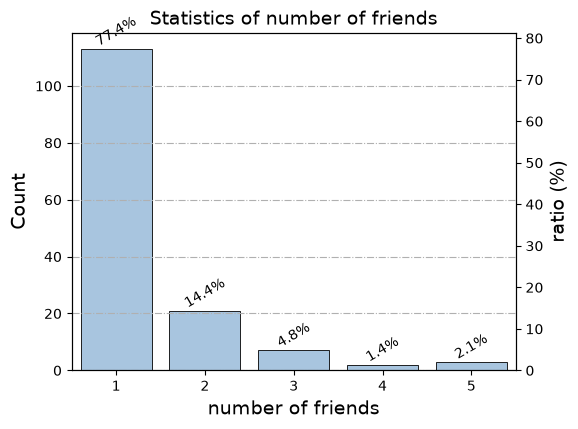

In [18]:
print(social_network_selected.friend_list.map(len).describe())
visual_statistics_discrete(social_network_selected.friend_list.map(len), "number of friends")

### Число категорий видео

count    10728.000000
mean         1.183166
std          0.436205
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: feat, dtype: float64


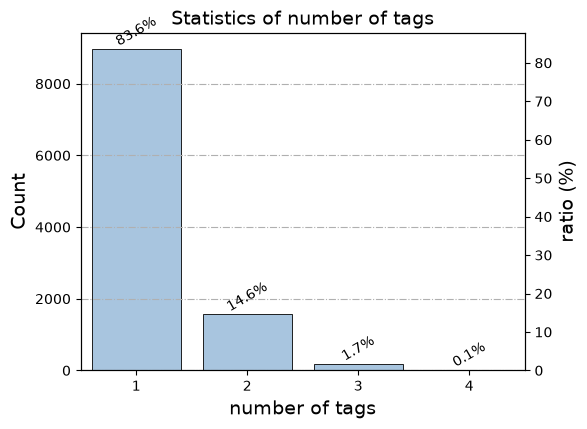

In [19]:
num_feat = item_categories.feat.map(len)
print(num_feat.describe())
visual_statistics_discrete(num_feat, "number of tags")

### Распределение категорий видео в train-каталоге

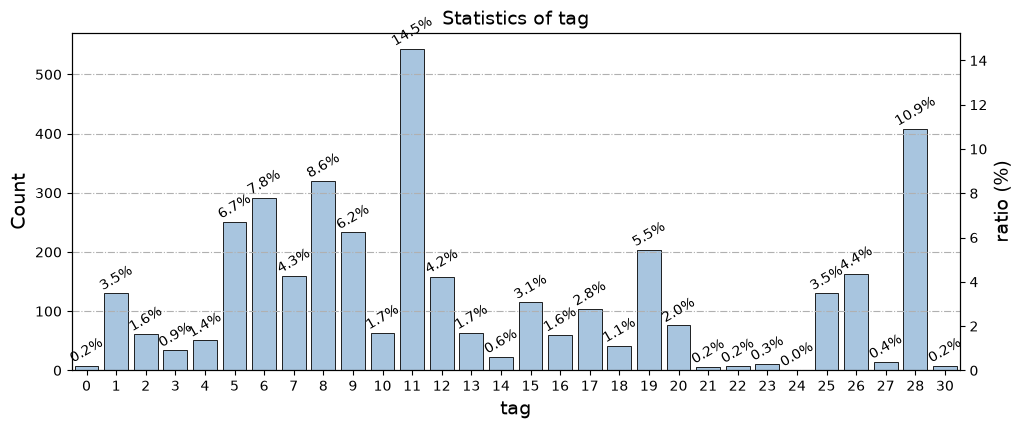

In [20]:
import collections
import itertools

cnt = item_categories_selected.feat.map(collections.Counter)
cnt_all = collections.Counter()
for d in cnt:
    cnt_all.update(d)
# print(dict(cnt_all))
all_feat = pd.Series(sorted(list(itertools.chain.from_iterable([[i]*k for i,k in cnt_all.items()]))),name="feat")
# print(all_feat)
visual_statistics_discrete(all_feat, "tag", size=(12,4.5))

### Распределение watch_ratio в big_matrix

count    1.241552e+07
mean     8.510664e-01
std      7.185296e-01
min      0.000000e+00
25%      3.111008e-01
50%      7.161066e-01
75%      1.161843e+00
max      5.000000e+00
Name: watch_ratio, dtype: float64


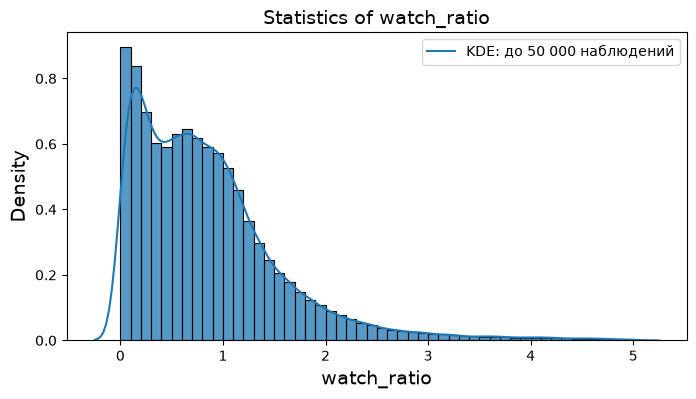

In [21]:
big_watch_ratio = big_matrix.watch_ratio[big_matrix.watch_ratio <= 5]
print(big_watch_ratio.describe())
visual_continue(big_watch_ratio)

### Распределение watch_ratio в подвыборке small_matrix

count    594167.000000
mean          0.858524
std           0.595434
min           0.000000
25%           0.470366
50%           0.771261
75%           1.114305
max           5.000000
Name: watch_ratio, dtype: float64


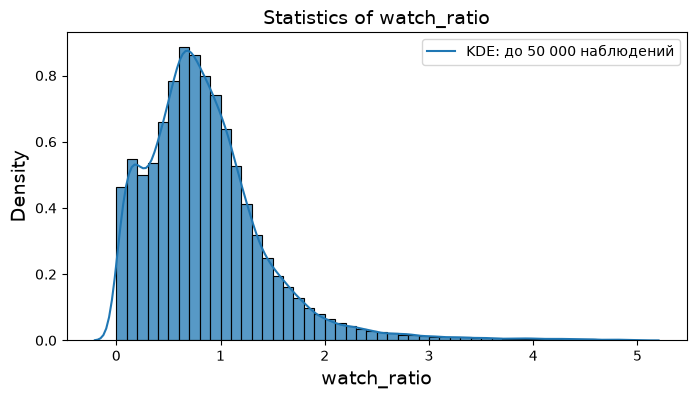

In [22]:
small_watch_ratio = small_df.watch_ratio[small_df.watch_ratio <= 5]
print(small_watch_ratio.describe())
visual_continue(small_watch_ratio)

### Длительность видео в big_matrix (миллисекунды)

count    1.253081e+07
mean     1.462157e+04
std      1.983474e+04
min      1.400000e+02
25%      7.434000e+03
50%      9.636000e+03
75%      1.217900e+04
max      3.150720e+05
Name: video_duration, dtype: float64


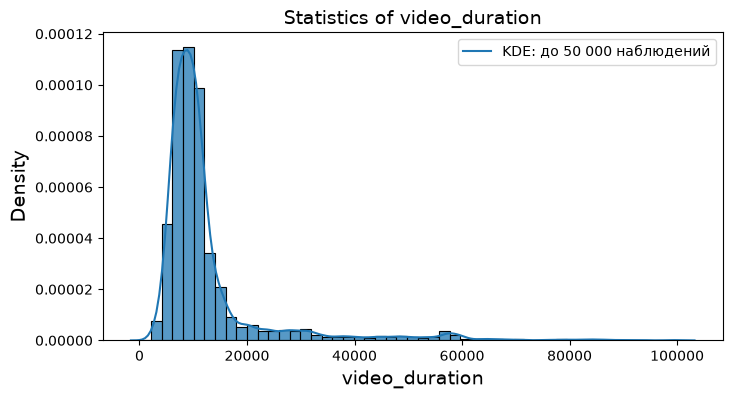

In [23]:
big_video_duration = big_matrix.video_duration
print(big_video_duration.describe())
# visual_continue(big_video_duration)
visual_continue(big_video_duration[big_video_duration < 100000])

### Длительность видео в small_matrix (миллисекунды)

count    597238.000000
mean      14308.949961
std       21650.291448
min        3270.000000
25%        7634.000000
50%        9557.000000
75%       11760.000000
max      315072.000000
Name: video_duration, dtype: float64


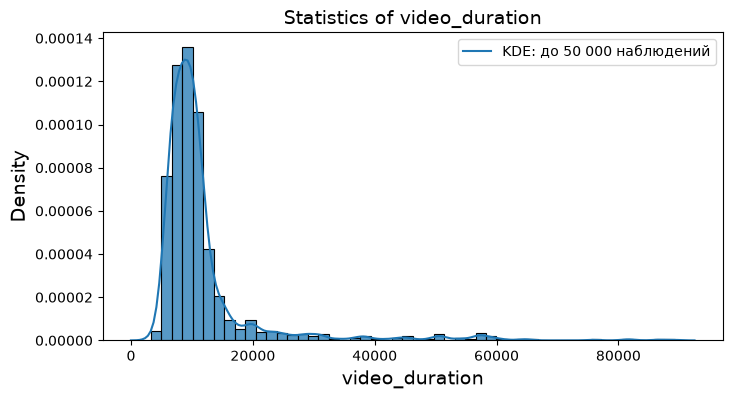

In [24]:
small_video_duration = small_df.video_duration
print(small_video_duration.describe())
visual_continue(small_video_duration[small_video_duration < 100000])

### Активность пользователей в big_matrix

               date
count   7176.000000
mean    1746.210424
std      991.832222
min      100.000000
25%      883.000000
50%     1846.500000
75%     2461.000000
max    16015.000000


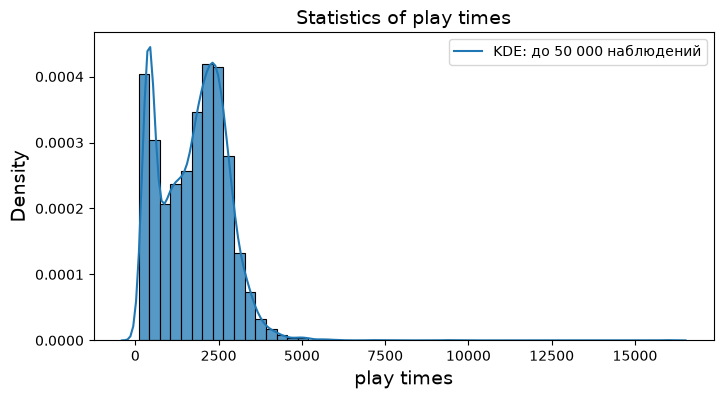

In [25]:
big_play_time = big_matrix.groupby('user_id').agg({"date":len})
big_play_time.name = "play times"
print(big_play_time.describe())
visual_continue(big_play_time)

### Активность пользователей в small_matrix

              date
count  1411.000000
mean   3314.365698
std       6.984852
min    3295.000000
25%    3309.000000
50%    3315.000000
75%    3320.000000
max    3327.000000


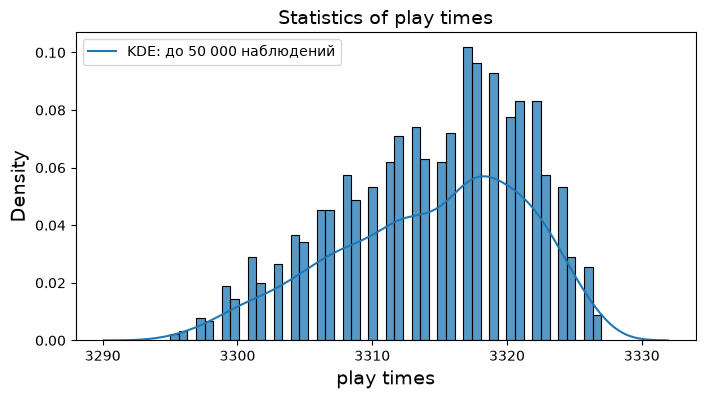

In [26]:
small_play_time = small_matrix.groupby('user_id').agg({"date":len})
small_play_time.name = "play times"
print(small_play_time.describe())
visual_continue(small_play_time)

### Дневная активность пользователей в big_matrix

count    188322.000000
mean         66.539257
std          78.752240
min           1.000000
25%          19.000000
50%          42.000000
75%          83.000000
max        3268.000000
Name: play times, dtype: float64


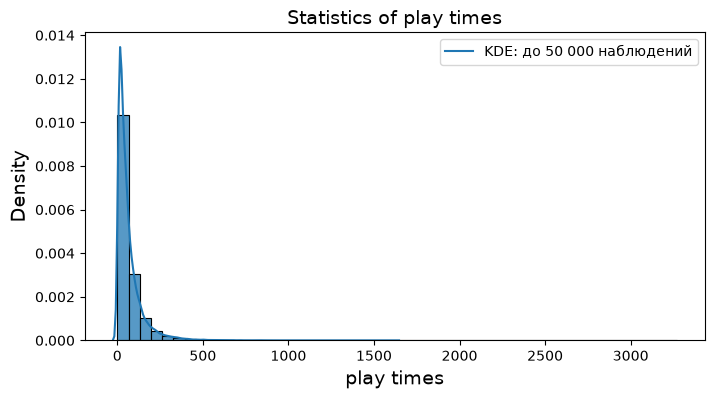

In [27]:
big_daily_play_time = big_matrix.groupby(['user_id', 'date']).size()
big_daily_play_time.name = "play times"
print(big_daily_play_time.describe())
visual_continue(big_daily_play_time)

### Дневная активность пользователей в small_matrix

count    86671.000000
mean        51.857922
std         32.608372
min          1.000000
25%         28.000000
50%         47.000000
75%         70.000000
max        402.000000
Name: play times, dtype: float64


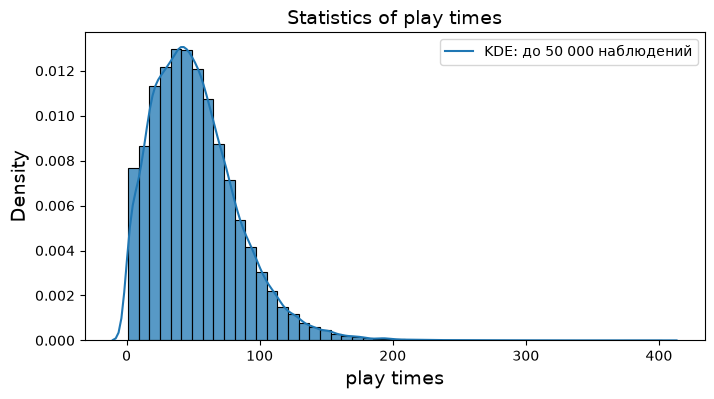

In [28]:
small_daily_play_time = small_matrix.groupby(['user_id', 'date']).size()
small_daily_play_time.name = "play times"
print(small_daily_play_time.describe())
visual_continue(small_daily_play_time)

### Популярность видео и активность пользователей в train

Число наблюдавшихся пар после агрегации повторов показывает неравномерность
поддержки пользователей и объектов. Нулевой watch_ratio остаётся наблюдением.

,Пар на пользователя,Пользователей на видео
count,2199.000000,3129.000000
mean,444.187358,312.166187
std,247.772235,364.523033
min,35.000000,1.000000
25%,199.500000,16.000000
50%,479.000000,104.000000
75%,644.000000,581.000000
max,1119.000000,1536.000000


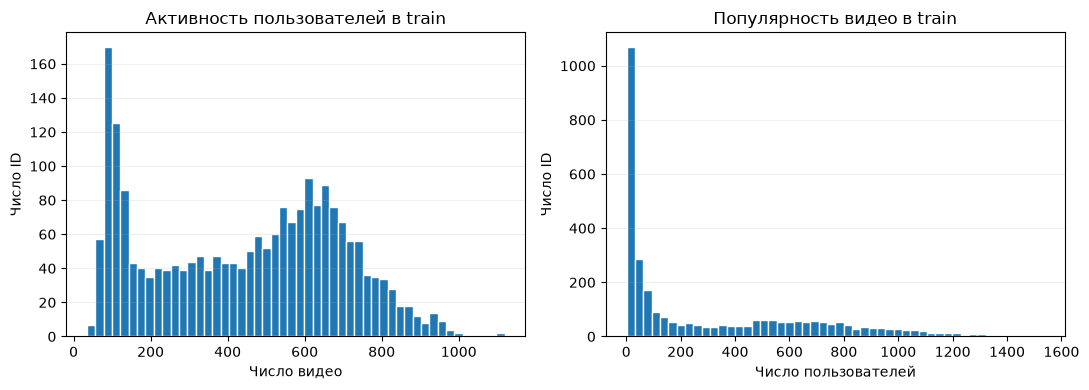

In [11]:
user_activity = train_df.groupby('user_id').size()
item_popularity = train_df.groupby('video_id').size()
display(pd.DataFrame({'Пар на пользователя': user_activity.describe(),
                      'Пользователей на видео': item_popularity.describe()}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title, xlabel in [
    (axes[0], user_activity, 'Активность пользователей в train', 'Число видео'),
    (axes[1], item_popularity, 'Популярность видео в train', 'Число пользователей'),
]:
    ax.hist(values, bins=50, edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Число ID')
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

## 3. Результаты и выводы после EDA

В результате EDA было решено использовать **big_matrix для обучения, валидации и основного тестирования**. Оценку на small_matrix сохраняем как дополнительную проверку переноса между режимами наблюдений.

Предварительная подготовка состоит из следующих шагов:

1. **Очистка взаимодействий.** Удаляем строки с пропусками в `timestamp`, `user_id`, `video_id` и `watch_ratio`, а также с бесконечным или отрицательным `watch_ratio`. В исходной small_matrix около 3,9% строк не имеют временной метки; в big_matrix таких пропусков нет. Без timestamp нельзя определить, к какому временному периоду относится взаимодействие.
2. **Воспроизводимая подвыборка.** Из очищенной big_matrix случайно выбираем 2200 пользователей и 4700 видео без возвращения, фиксируя `SEED=42`. В обеих матрицах оставляем только выбранные ID. Так ограничиваем вычислительные затраты и сохраняем одинаковый принцип отбора данных для всех моделей.
3. **Временное разбиение.** По timestamp выбранной big_matrix находим границы $t_1$ и $t_2$ — квантили 0,70 и 0,85. Train содержит события big_matrix с $t\leq t_1$, validation — события с $t_1<t\leq t_2$. Основной test формируется из big_matrix с $t>t_2$; события small_matrix после той же границы используются для дополнительной оценки. Это позволяет обучаться на прошлом, подбирать параметры на более поздних событиях и проверять результат на ещё более поздних. Последние 15% выбранной big_matrix образуют основной test до фильтрации новых ID и известных пар.
4. **Обработка новых пользователей и видео.** В validation и test оставляем только ID, присутствующие в train. Таким образом, сравниваем все методы в одинаковой постановке без холодного старта; качество на новых пользователях и объектах отдельно не оцениваем.
5. **Агрегация повторных просмотров.** Для построения матриц берём средний `watch_ratio` каждой пары пользователь–видео отдельно внутри train, validation и test. Усреднение не смешивает временные периоды. Полные дубликаты строк отдельно не удаляем; их значения также входят в это среднее. Нулевой `watch_ratio` сохраняем: это наблюдавшийся просмотр с нулевым сигналом, а не отсутствие взаимодействия.
6. **Подготовка метаданных.** Для FM используем категории видео из `item_categories.feat` как статические описания содержания. Профили пользователей, социальные связи и дневные статистики анализируем в EDA, но не включаем в модель: в этой работе не установлено, какие из этих значений были доступны в момент рекомендации.

При `SEED=42` получены следующие размеры после подготовки пар и фильтрации отложенных выборок по релевантности и известной истории. Train содержит все обучающие пары; validation и test — только релевантные пары для оценки:

| Часть | Взаимодействия | Пользователи | Видео |
|---|---:|---:|---:|
| Train | 976 768 | 2 199 | 3 129 |
| Validation | 31 695 | 2 076 | 1 149 |
| Test (big_matrix) | 11 897 | 1 803 | 534 |
| Test (small_matrix, дополнительно) | 296 | 189 | 86 |

### Метрики при K = 10

Качество top-10 рекомендаций оценивается по **Recall@10** и **NDCG@10**. Основная метрика выбора гиперпараметров — NDCG@10.

Релевантными считаются видео с `watch_ratio` не ниже 0,8. Для пользователя $u$ множество $G_u$ содержит релевантные видео из отложенной выборки, доступные к рекомендации; $L_u^{10}$ — список до десяти рекомендаций.

$$
\operatorname{Recall@10}(u)=\frac{|L_u^{10}\cap G_u|}{|G_u|}.
$$
Recall@10 измеряет долю найденных релевантных видео. NDCG@10 дополнительно учитывает их позиции:
$$
\operatorname{DCG@10}(u)=\sum_{j=1}^{|L_u^{10}|}\frac{\mathbb{1}[i_j\in G_u]}{\log_2(j+1)},\qquad
\operatorname{NDCG@10}(u)=\frac{\operatorname{DCG@10}(u)}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.
$$

Для всех моделей используются одинаковые разбиения, каталог train и правила исключения известных видео: на validation исключаются train-просмотры, на test — train и validation. Множество $G_u$ строится с теми же исключениями. Метрики усредняются по пользователям с непустым $G_u$; отсутствие рекомендаций даёт нулевое качество.

Параметры выбираются по validation NDCG@10. Для итоговой оценки используются выбранные модели, обученные на train; test не участвует в подборе параметров.

In [8]:
from utils.evaluation import eligible_truth, ranking_metrics, grid_search

RELEVANCE_THRESHOLD = 0.8
validation_truth = eligible_truth(val_df, train_df, users, items, RELEVANCE_THRESHOLD)
assert not validation_truth.empty, 'Нет доступных релевантных объектов validation'
print('Пользователей для validation:', validation_truth.user_id.nunique())

Пользователей для validation: 2076


## 4. Модели и подбор гиперпараметров

**Постановка задачи**

Пусть $U$ — множество пользователей, $I$ — множество видео, тогда обучающее множество имеет вид:
$$
D_{\mathrm{train}}=\{(u,i,t,r):u\in U,\ i\in I\},
$$
где $t$ — временная метка, $r$ — отношение длительности просмотра к длительности видео (`watch_ratio`). 
Определим матрицу взаимодействий и отдельную маску наблюдений:
$$
R_{ui}=\begin{cases} r_{ui},&(u,i)\in\Omega,\\0,&(u,i)\notin\Omega,\end{cases}
\qquad M_{ui}=\mathbb{1}[(u,i)\in\Omega],
$$
где $\Omega$ — множество наблюдавшихся в train пар. Разделение $R$ и $M$ позволяет отличать нулевой просмотр от отсутствия просмотра.

В KNN и EASE используется непрерывный сигнал $R$. Для FM ограничиваем его диапазоном $[0,1]$, чтобы повторные просмотры не создавали чрезмерно большие таргеты. Базовая iALS использует бинарный таргет $M$, а пятая модель — непрерывный таргет на основе степени просмотра.

Каждая модель вычисляет оценку $s(u,i)$ для допустимого кандидата и рекомендует пользователю топ-10 видео с максимальными оценками:
$$
L_u^{10}=\operatorname{Top10}_{i\in I_{\mathrm{cand}}(u)}s(u,i).
$$

In [9]:
from models.userknn import UserKNN
from models.als import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomALS

from utils.visualization import (plot_loss_history, plot_validation_search, plot_search_heatmap,
                           plot_model_comparison,
                           plot_knn_search, plot_parameter_curve, plot_ease_objective, plot_fm_search)

search_results = {}
best_models = {}
best_parameters = {}

### Коллаборативная KNN фильтрация

**Описание подхода «User-based collaborative filtering»**

Метод предполагает, что пользователи с похожими историями взаимодействий могут иметь похожие интересы. Для оценки нового видео используем сигналы наиболее похожих пользователей, которые его уже смотрели.

**Fit**

1. Строим матрицу сигналов $R$ и маску наблюдений $M$ по train.
2. Между всеми пользователями вычисляем сходство. Его вид — гиперпараметр модели.

Для **косинусного сходства** сравниваем полные строки матрицы с нулями для отсутствующих взаимодействий:
$$
\operatorname{sim}_{\cos}(u,v)=
\frac{\sum_{i\in I}R_{ui}R_{vi}}
{\sqrt{\sum_{i\in I}R_{ui}^{2}}\sqrt{\sum_{i\in I}R_{vi}^{2}}}.
$$

Для **корреляции Пирсона** используем только совместно наблюдавшиеся видео
$$
C_{uv}=\{i:M_{ui}=1,\ M_{vi}=1\}.
$$
Средние значения $\mu_{u|uv}$ и $\mu_{v|uv}$ также вычисляем на этом пересечении:
$$
\operatorname{sim}_{\mathrm{Pearson}}(u,v)=
\frac{\sum_{i\in C_{uv}}(R_{ui}-\mu_{u|uv})(R_{vi}-\mu_{v|uv})}
{\sqrt{\sum_{i\in C_{uv}}(R_{ui}-\mu_{u|uv})^2}
 \sqrt{\sum_{i\in C_{uv}}(R_{vi}-\mu_{v|uv})^2}}.
$$

3. Исключаем самого пользователя и выбираем $N_k(u)$ — до $k$ пользователей с наибольшими положительными сходствами. Если таких пользователей меньше $k$, используем всех доступных.

Отрицательная корреляция означает противоположные отклонения сигналов на общих видео. Здесь используем соседей как источники похожих предпочтений и усредняем их неотрицательные сигналы с положительными весами.

**Predict**

Для видео $i$, не наблюдавшегося у пользователя $u$, вычисляем взвешенное среднее:
$$
s(u,i)=
\frac{\sum_{v\in N_k(u)}\operatorname{sim}(u,v)R_{vi}}
{\sum_{v\in N_k(u)}\operatorname{sim}(u,v)M_{vi}}.
$$

Для каждого пользователя исключаем уже просмотренные им видео и сортируем оставшиеся по $s(u,i)$, выбираем top-10.

**Гиперпараметры**

- Мера сходства: `cosine` или `pearson`.
- Максимальное число соседей $k$: 5, 10, 20, 50, 100, 200, 500.

In [31]:
knn_grid = {'similarity': ['cosine', 'pearson'], 'k': [5, 10, 20, 50, 100, 200, 500]}
best_models['UserKNN'], best_parameters['UserKNN'], search_results['UserKNN'] = grid_search(
    UserKNN, knn_grid, train_df, validation_truth)
display(search_results['UserKNN'])

UserKNN {'similarity': 'cosine', 'k': 5} {'Recall@10': 0.00441846347914569, 'NDCG@10': 0.006277309613117868, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 10} {'Recall@10': 0.0031328114272855625, 'NDCG@10': 0.004173191106849579, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 20} {'Recall@10': 0.0023854535394167574, 'NDCG@10': 0.003191807330001034, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 50} {'Recall@10': 0.001320808731167254, 'NDCG@10': 0.0019750705674851563, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 100} {'Recall@10': 0.0008302282802725464, 'NDCG@10': 0.0011253329940477735, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 200} {'Recall@10': 0.00017272564131625676, 'NDCG@10': 0.00024785385685765896, 'n_users': 2076}
UserKNN {'similarity': 'cosine', 'k': 500} {'Recall@10': 0.00023966275795733388, 'NDCG@10': 0.0003639897828012748, 'n_users': 2076}
UserKNN {'similarity': 'pearson', 'k': 5} {'Recall@10': 0.00142180533589994, 'NDCG@10': 0.0

,similarity,k,Recall@10,NDCG@10,n_users,seconds
0,cosine,5,0.004418,0.006277,2076,3.496326
1,cosine,10,0.003133,0.004173,2076,3.521302
2,cosine,20,0.002385,0.003192,2076,3.675926
3,cosine,50,0.001321,0.001975,2076,3.764416
4,cosine,100,0.000830,0.001125,2076,3.282979
5,cosine,200,0.000173,0.000248,2076,3.754896
6,cosine,500,0.000240,0.000364,2076,5.231817
7,pearson,5,0.001422,0.002201,2076,7.080654
8,pearson,10,0.000768,0.001866,2076,7.073353
9,pearson,20,0.001478,0.002679,2076,7.045821


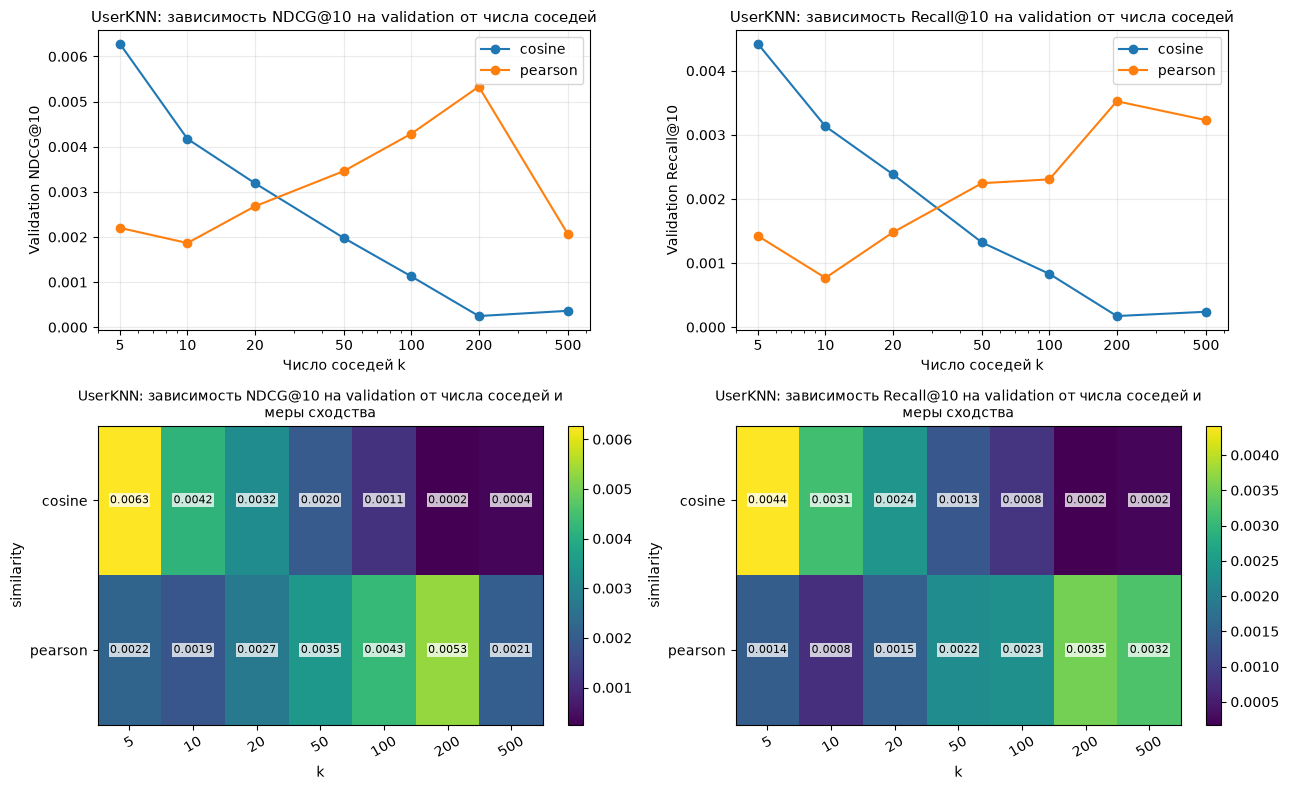

In [12]:
plot_knn_search(search_results['UserKNN'])

In [33]:
recommendations = best_models['UserKNN'].recommend(validation_truth.user_id.unique(), n=10)

In [34]:
recommendations

,user_id,video_id,predicted_score
0,8,2118,2.988156
1,8,2111,2.858205
2,8,7664,2.816566
3,8,10261,2.449244
4,8,6099,2.356948
...,...,...,...
20755,7174,10302,2.708005
20756,7174,5170,2.671229
20757,7174,6947,2.582665
20758,7174,4374,2.536082


### ALS

**Описание подхода «Alternating Least Squares» для неявной обратной связи (iALS)**

Метод представляет предпочтения пользователей произведением двух матриц низкого ранга:
$$
P\approx XY^{\top},\qquad
X\in\mathbb R^{|U|\times f},\quad Y\in\mathbb R^{|I|\times f},
$$
где $f$ — число латентных факторов, $x_u$ — вектор пользователя, $y_i$ — вектор видео. Скалярное произведение $x_u^{\top}y_i$ служит оценкой предпочтения.

**Train**

1. Задаём бинарный таргет и уверенность:
$$
p_{ui}^{\mathrm{bin}}=M_{ui},\qquad c_{ui}=1+\alpha M_{ui},\qquad\alpha=10.
$$
Любая наблюдавшаяся пара, включая нулевой просмотр, получает таргет 1 и вес $1+\alpha$, а ненаблюдавшаяся пара получает таргет 0 с меньшим весом 1: отсутствие просмотра не считается столь же надёжным отрицательным сигналом.

2. Инициализируем $Y$ небольшими случайными значениями с фиксированным seed. Матрицу $X$ получаем на первом шаге оптимизации. Решаем задачу минимизации регуляризованной квадратичной ошибки на наблюдениях:
$$
L(X,Y)=\sum_{u\in U}\sum_{i\in I}
c_{ui}\bigl(p_{ui}^{\mathrm{bin}}-x_u^{\top}y_i\bigr)^2
+\lambda\bigl(\|X\|_F^2+\|Y\|_F^2\bigr).
$$

3. Поочерёдно обновляем факторы.

**Шаг по $X$.** Фиксируем $Y$, обозначаем $\Omega_u=\{i:M_{ui}=1\}$ и решаем для каждого пользователя:
$$
\underbrace{\left(Y^{\top}Y+\alpha Y_{\Omega_u}^{\top}Y_{\Omega_u}+\lambda I_f\right)}_{A_u}x_u
=
\underbrace{(1+\alpha)Y_{\Omega_u}^{\top}p_{u,\Omega_u}^{\mathrm{bin}}}_{b_u}.
$$
Здесь $Y_{\Omega_u}$ — строки факторов просмотренных видео. Член $Y^{\top}Y$ учитывает базовый вес всех пар, а добавка с $\alpha$ повышает вес наблюдавшихся.

**Шаг по $Y$.** Фиксируем обновлённую $X$, обозначаем $\Omega^i=\{u:M_{ui}=1\}$ и решаем для каждого видео:
$$
\left(X^{\top}X+\alpha X_{\Omega^i}^{\top}X_{\Omega^i}+\lambda I_f\right)y_i
=(1+\alpha)X_{\Omega^i}^{\top}p_{\Omega^i,i}^{\mathrm{bin}}.
$$
В коде используем `np.linalg.solve(A, b)` вместо явного вычисления обратной матрицы. Оба шага повторяются $n_{\mathrm{iter}}$ раз.

**Predict**

Для пары пользователь–видео вычисляем
$$
s(u,i)=x_u^{\top}y_i.
$$
Исключаем известные видео и рекомендуем top-10 по убыванию этой оценки.

**Гиперпараметры**

- Число латентных факторов $f$: 8, 16, 32.
- Коэффициент L2-регуляризации $\lambda$: 0.01, 0.1, 1.0.
- Число полных чередований $n_{\mathrm{iter}}$: 10, 20, 30, 50.

$\alpha=10$ фиксирован; это же значение используются в пятой модели.

In [35]:
als_grid = {'n_factors': [8, 16, 32], 'reg': [0.01, 0.1, 1.0], 'n_iter': [10, 20, 30, 50],
            'alpha': [10.0], 'random_state': [SEED]}
best_models['iALS'], best_parameters['iALS'], search_results['iALS'] = grid_search(
    ImplicitALS, als_grid, train_df, validation_truth)
display(search_results['iALS'])

ImplicitALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.0283668520864778, 'NDCG@10': 0.03913574606366347, 'n_users': 2076}
ImplicitALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 20, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.02930141438532681, 'NDCG@10': 0.03781352118803509, 'n_users': 2076}
ImplicitALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 30, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.029092337140250654, 'NDCG@10': 0.03827310699165315, 'n_users': 2076}
ImplicitALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 50, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.02937471888673622, 'NDCG@10': 0.03858556549454518, 'n_users': 2076}
ImplicitALS {'n_factors': 8, 'reg': 0.1, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.028924469887328462, 'NDCG@10': 0.038910420607219866, 'n_users': 2076}
ImplicitALS {'n_factors': 8, 'reg': 0.1, 'n_iter': 20, 'alpha': 10.0, 'random_state': 42} {'Recall@10': 0.029364074193633922

,n_factors,reg,n_iter,alpha,random_state,Recall@10,NDCG@10,n_users,seconds
0,8,0.01,10,10.0,42,0.028367,0.039136,2076,11.032672
1,8,0.01,20,10.0,42,0.029301,0.037814,2076,19.845119
2,8,0.01,30,10.0,42,0.029092,0.038273,2076,28.019824
3,8,0.01,50,10.0,42,0.029375,0.038586,2076,45.990378
4,8,0.10,10,10.0,42,0.028924,0.038910,2076,10.491121
5,8,0.10,20,10.0,42,0.029364,0.037962,2076,19.656637
6,8,0.10,30,10.0,42,0.029134,0.038326,2076,27.697614
7,8,0.10,50,10.0,42,0.029378,0.038576,2076,45.423571
8,8,1.00,10,10.0,42,0.028626,0.038597,2076,10.347986
9,8,1.00,20,10.0,42,0.028786,0.037958,2076,18.892140


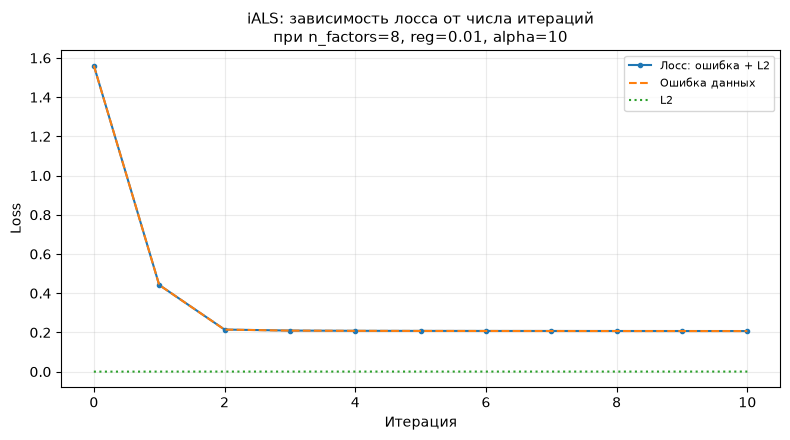

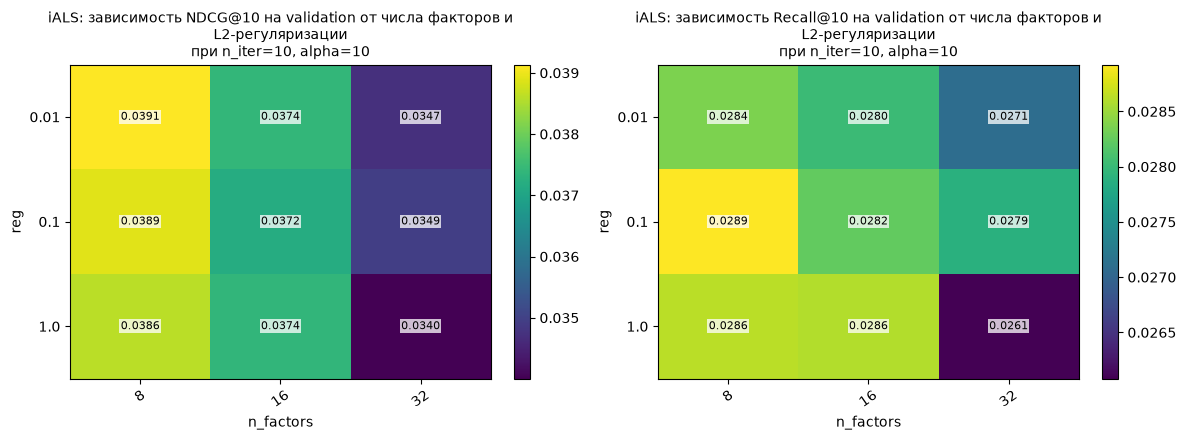

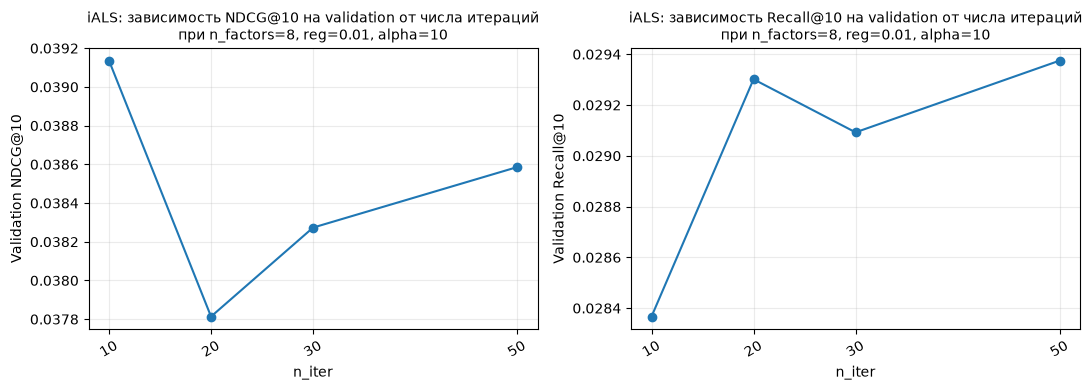

In [13]:
plot_loss_history(best_models['iALS'], 'iALS')
plot_search_heatmap(search_results['iALS'], best_parameters['iALS'], 'iALS', 'reg', 'n_factors')
plot_parameter_curve(search_results['iALS'], best_parameters['iALS'], 'iALS', 'n_iter')

### EASE

**Описание подхода «Embarrassingly Shallow Autoencoders for Sparse Data»**


Идея метода заключается в обучении линейного преобразования истории взаимодействия между пользователями и объектами в полную матрицу взаимодействий.

EASE - линейный автоэнкодер без скрытого слоя и без нелинейности:
вход - строка пользователя $r_u \in \mathbb{R}^{n_i}$, выход - $r_u B$,
где $B \in \mathbb{R}^{n_i \times n_i}$ - обученная матрица преобразования. Накладывается ограничение $\mathrm{diag}(B) = 0$, которое не дает модели тривиально скопировать вход.

**Fit**

1. Минимизируем регуляризованную ошибку реконструкции:
$$
L(B)=\|R-RB\|_F^2+\lambda\|B\|_F^2,
\qquad\operatorname{diag}(B)=0.
$$
2. Находим замкнутое решение. Вычисляем матрицу Грама и регуляризованную обратную матрицу:
$$
G=R^{\top}R,\qquad P=(G+\lambda I)^{-1}.
$$

3. Тогда матрица $B$ имеет вид:
$$
B_{ij}=-\frac{P_{ij}}{P_{jj}}\quad(i\ne j),\qquad B_{ii}=0. \quad \text{--- нормируем столбцы и обнуляем диагональ}
$$


**Predict**

Аналогично предыдущим методам для каждого пользоваля и видео, которое он не просмотрел, вычисляем:
$$
s(u,i)=(r_uB)_i=\sum_{j:(u,j)\in\Omega}R_{uj}B_{ji}.
$$
Это скалярное произведение строки истории на $i$-й столбец матрицы связей: каждое просмотренное видео вносит свой вклад в оценку кандидата. Веса могут быть отрицательными.

После исключения известных видео ранжируем кандидатов по $s(u,i)$ и рекомендуем top-10.

**Гиперпараметр**

- Коэффициент L2-регуляризации $\lambda$: 1, 3, 10, 30, 100, 300, 1000, 3000.

In [37]:
ease_grid = {'reg': [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0]}
best_models['EASE'], best_parameters['EASE'], search_results['EASE'] = grid_search(
    EASE, ease_grid, train_df, validation_truth)
display(search_results['EASE'])

EASE {'reg': 1.0} {'Recall@10': 0.009622689621842834, 'NDCG@10': 0.016370333100630338, 'n_users': 2076}
EASE {'reg': 3.0} {'Recall@10': 0.010385292271038595, 'NDCG@10': 0.01749686223394016, 'n_users': 2076}
EASE {'reg': 10.0} {'Recall@10': 0.011003913893501414, 'NDCG@10': 0.018806509825874895, 'n_users': 2076}
EASE {'reg': 30.0} {'Recall@10': 0.012823081022940917, 'NDCG@10': 0.020977389455656286, 'n_users': 2076}
EASE {'reg': 100.0} {'Recall@10': 0.013947876835262617, 'NDCG@10': 0.023053015616044868, 'n_users': 2076}
EASE {'reg': 300.0} {'Recall@10': 0.01592500681630556, 'NDCG@10': 0.02510126630315856, 'n_users': 2076}
EASE {'reg': 1000.0} {'Recall@10': 0.018446691101190762, 'NDCG@10': 0.027176085484253404, 'n_users': 2076}
EASE {'reg': 3000.0} {'Recall@10': 0.019148781959669632, 'NDCG@10': 0.028273851730376727, 'n_users': 2076}


,reg,Recall@10,NDCG@10,n_users,train_objective,train_reconstruction,train_regularization,weight_norm_squared,seconds
0,1.0,0.009623,0.016370,2076,0.007543,0.001576,0.005967,41055.840115,6.614331
1,3.0,0.010385,0.017497,2076,0.016768,0.005652,0.011116,25496.176294,6.588535
2,10.0,0.011004,0.018807,2076,0.034448,0.015918,0.018530,12749.589349,6.563075
3,30.0,0.012823,0.020977,2076,0.059170,0.032474,0.026696,6122.871306,6.270845
4,100.0,0.013948,0.023053,2076,0.097442,0.060323,0.037119,2554.023012,5.049848
5,300.0,0.015925,0.025101,2076,0.143861,0.096475,0.047386,1086.828339,4.650184
6,1000.0,0.018447,0.027176,2076,0.207005,0.150193,0.056812,390.906957,4.696809
7,3000.0,0.019149,0.028274,2076,0.271500,0.212307,0.059193,135.762755,4.814003


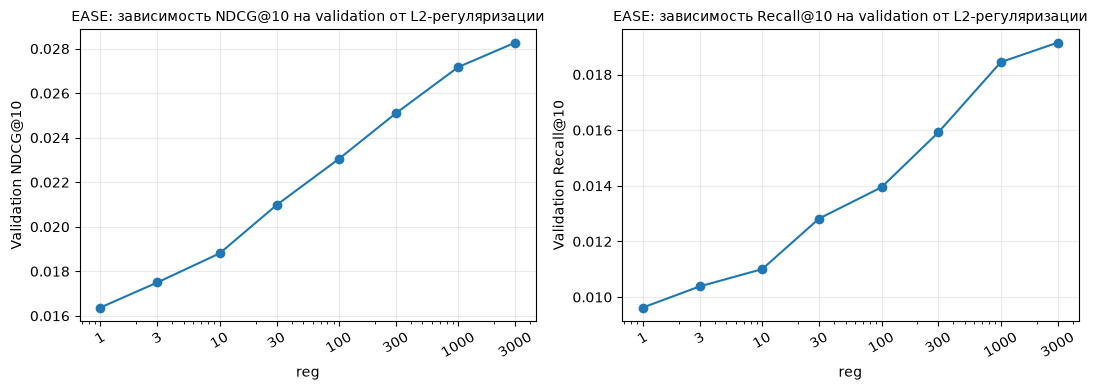

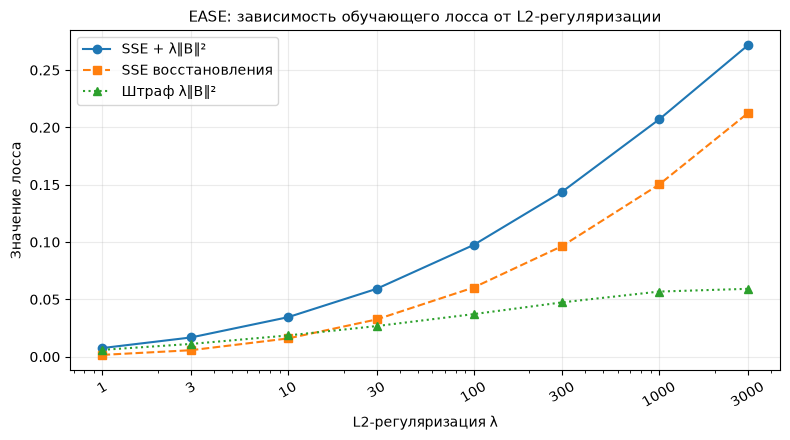

In [14]:
plot_parameter_curve(search_results['EASE'], best_parameters['EASE'], 'EASE', 'reg')
plot_ease_objective(search_results['EASE'])

### Факторизационные машины

**Описание подхода «Factorization Machine (FM) с метапризнаками»**

**Представление пары пользователь–видео**

Для каждой пары $(u,i)$ формируется разреженный вектор признаков $\mathbf x_{ui}\in\mathbb R^p$. В текущей реализации он включает one-hot ID пользователя, one-hot ID видео и multi-hot категории видео из `item_categories.feat`. Например, при двух категориях в строке активны четыре признака: пользователь, видео и две категории. Для видео без категорий предусмотрен отдельный индикатор.

Категории описывают содержание и позволяют совместно обучать взаимодействия пользователя с тематикой разных видео. Их рассматриваем как статические метаданные. Не используем в качестве входных признаков фактический `watch_ratio`, длительность просмотра оцениваемого взаимодействия и будущие дневные агрегаты. Из профилей пользователей и динамических признаков здесь не формируем признаки, поскольку не установлена их доступность на момент рекомендации.

**Функция предсказания**

FM второго порядка вычисляет оценку
$$
\widehat y(\mathbf x)=w_0+\sum_{j=1}^{p}w_jx_j+
\sum_{j=1}^{p}\sum_{\ell=j+1}^{p}
\langle\mathbf v_j,\mathbf v_\ell\rangle x_jx_\ell,
$$
где $w_0\in\mathbb R$ - смещение, $w_j\in\mathbb R$ - линейные коэффициенты, а $\mathbf v_j\in\mathbb R^k$ - латентный вектор признака $j$. Скалярное произведение $\langle\mathbf v_j,\mathbf v_\ell\rangle$ задаёт силу взаимодействия двух признаков.

Для эффективного вычисления попарного члена используется тождество
$$
\sum_{j=1}^{p}\sum_{\ell=j+1}^{p}
\langle\mathbf v_j,\mathbf v_\ell\rangle x_jx_\ell=\frac12\left\|\sum_{j=1}^{p}\mathbf v_jx_j\right\|_2^2
-\frac12\sum_{j=1}^{p}\|\mathbf v_j\|_2^2x_j^2
$$
Это сокращает вычисление с явного перебора всех пар признаков до порядка $O(pk)$ для плотного вектора признаков; для разреженного представления расчёт зависит от числа активных признаков.

**Train**

В данной работе FM обучается как регрессия непрерывного сигнала на наблюдавшихся взаимодействиях. После усреднения повторных просмотров задаём $\tilde r_{ui}=\operatorname{clip}(R_{ui},0,1)$: клиппинг ограничивает влияние больших отношений просмотра.

Для обучающего пакета $\mathcal B$ минимизируем
$$
L_{\mathcal B}=\frac{1}{|\mathcal B|}\sum_{(u,i)\in\mathcal B}\bigl(\tilde r_{ui}-\widehat y(\mathbf x_{ui})\bigr)^2+\lambda\left(\|w\|_2^2+\sum_{j=1}^{p}\|\mathbf v_j\|_2^2\right).
$$
В текущем коде коэффициент регуляризации общий для линейных весов и факторов; смещение $w_0$ не регуляризуется.

1. Инициализируем смещение средним таргета, линейные веса нулями, факторы небольшими случайными значениями.
2. На каждой эпохе перемешиваем обучающие пары с фиксированным seed и делим их на пакеты.
3. Самостоятельно вычисляем предсказания, MSE с L2 и аналитические градиенты; обновляем параметры алгоритмом Adam на NumPy/SciPy.
4. Повторяем обучение 10 эпох. Размер пакета — 2048. Дополнительные отрицательные пары не генерируем: примерами служат наблюдавшиеся просмотры с разной степенью интереса.

**Predict**

Для каждого видео-кандидата формируем вектор $\mathbf x_{ui}$ с тем же кодированием и вычисляем $s(u,i)=\widehat y(\mathbf x_{ui})$. Исключаем известные видео, сортируем кандидатов по оценке и выбираем top-10. Предсказания не обязаны лежать в $[0,1]$: это регрессионные оценки для ранжирования.

Метапризнаки в принципе могут помогать при холодном старте, но текущая реализация и общий протокол оценивают только ID из train. Отдельная обработка неизвестных пользователей и видео здесь не реализована.

**Гиперпараметры**

- Число латентных факторов признаков: 8, 16, 32.
- Коэффициент L2-регуляризации: $10^{-5}$, $10^{-4}$, $10^{-3}$.
- Скорость обучения Adam: 0.001, 0.005, 0.01.

Число факторов задаёт ёмкость взаимодействий, L2 ограничивает переобучение, скорость обучения влияет на сходимость. Число эпох, размер пакета и seed фиксированы.

In [39]:
fm_grid = {'n_factors': [8, 16, 32], 'reg': [1e-5, 1e-4, 1e-3],
           'learning_rate': [0.001, 0.005, 0.01], 'n_iter': [10], 'random_state': [SEED]}
best_models['FM'], best_parameters['FM'], search_results['FM'] = grid_search(
    FactorizationMachine, fm_grid, train_df, validation_truth,
    fit_kwargs={'item_categories': item_categories_selected})
display(search_results['FM'])

FactorizationMachine {'n_factors': 8, 'reg': 1e-05, 'learning_rate': 0.001, 'n_iter': 10, 'random_state': 42} {'Recall@10': 0.0010452695893024607, 'NDCG@10': 0.0014095513964009225, 'n_users': 2076}
FactorizationMachine {'n_factors': 8, 'reg': 1e-05, 'learning_rate': 0.005, 'n_iter': 10, 'random_state': 42} {'Recall@10': 0.0012824606575335506, 'NDCG@10': 0.0018746427840043082, 'n_users': 2076}
FactorizationMachine {'n_factors': 8, 'reg': 1e-05, 'learning_rate': 0.01, 'n_iter': 10, 'random_state': 42} {'Recall@10': 0.0005492307595930776, 'NDCG@10': 0.0007388728153119987, 'n_users': 2076}
FactorizationMachine {'n_factors': 8, 'reg': 0.0001, 'learning_rate': 0.001, 'n_iter': 10, 'random_state': 42} {'Recall@10': 0.0009110354316807434, 'NDCG@10': 0.0013525066830395306, 'n_users': 2076}
FactorizationMachine {'n_factors': 8, 'reg': 0.0001, 'learning_rate': 0.005, 'n_iter': 10, 'random_state': 42} {'Recall@10': 0.00042735846292247945, 'NDCG@10': 0.0011709338536727918, 'n_users': 2076}
Factoriz

,n_factors,reg,learning_rate,n_iter,random_state,Recall@10,NDCG@10,n_users,seconds
0,8,0.00001,0.001,10,42,0.001045,0.001410,2076,14.321262
1,8,0.00001,0.005,10,42,0.001282,0.001875,2076,13.525382
2,8,0.00001,0.010,10,42,0.000549,0.000739,2076,13.573399
3,8,0.00010,0.001,10,42,0.000911,0.001353,2076,14.180646
4,8,0.00010,0.005,10,42,0.000427,0.001171,2076,14.004215
5,8,0.00010,0.010,10,42,0.000554,0.001068,2076,13.553482
6,8,0.00100,0.001,10,42,0.005823,0.008501,2076,12.035320
7,8,0.00100,0.005,10,42,0.003625,0.004988,2076,11.996277
8,8,0.00100,0.010,10,42,0.003596,0.006089,2076,12.042089
9,16,0.00001,0.001,10,42,0.002204,0.002366,2076,15.277890


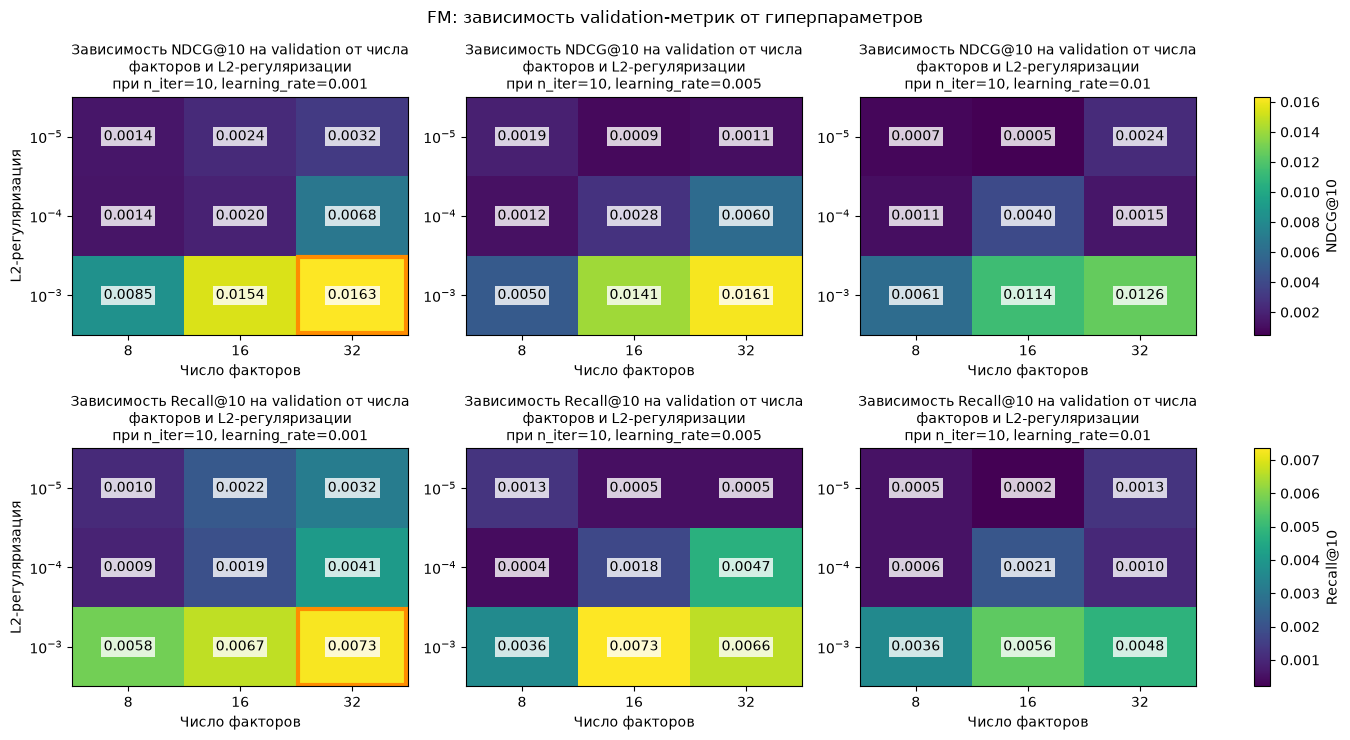

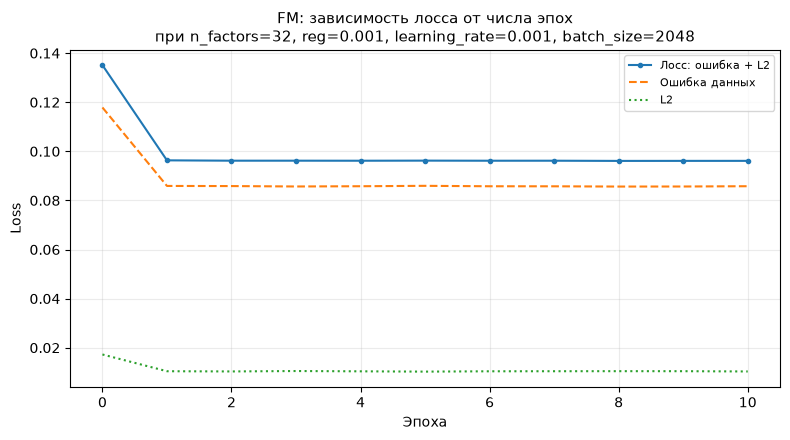

In [15]:
plot_fm_search(search_results['FM'], best_parameters['FM'])
plot_loss_history(best_models['FM'], 'FM')

**Проверка кодирования FM.** `user_id` и `video_id` — категории, даже если в CSV они записаны числами. Их one-hot-столбцы и multi-hot-столбцы категорий принимают значения 0/1. Ни номера категорий, ни величина ID не используются как численные значения. Численных входных признаков в этой версии нет, поэтому масштабировать нечего. Если добавлять, например, длительность видео, параметры масштабирования нужно будет оценивать только по train. Ниже показаны активные столбцы одной реальной пары.

In [16]:
fm = best_models['FM']
example_item = max(range(len(fm.items_)), key=lambda i: len(fm.item_tags_[i]))
example = fm._features(np.array([0]), np.array([example_item]))
active = example.indices
print('Входы FM: one-hot user/video и multi-hot категории; численных признаков нет.')
print('Число столбцов признаков:', fm.n_features_)
print('Пользователь:', fm.users_[0], 'видео:', fm.items_[example_item])
display(pd.DataFrame({'feature': [fm.feature_names_[j] for j in active],
                      'encoded_value': example.data}))

Входы FM: one-hot user/video и multi-hot категории; численных признаков нет.
Число столбцов признаков: 5358
Пользователь: 8 видео: 689


,feature,encoded_value
0,user_id=8,1.0
1,video_id=689,1.0
2,category=11,1.0
3,category=15,1.0
4,category=19,1.0
5,category=8,1.0


### Модель 5: iALS с собственным целевым сигналом

**Мотивация**

В базовой iALS все наблюдавшиеся пары имеют целевое значение 1. Поэтому различие между коротким и длительным просмотром напрямую не отражается в лоссе. В модифицированной модели используем относительное время просмотра как непрерывный сигнал предпочтения.

Для наблюдавшихся пар определим
$$
p_{ui}^{\mathrm{custom}}=
\begin{cases}
\left(\min\{1,\max\{0,R_{ui}\}\}\right)^{\gamma},&M_{ui}=1,\\
0,&M_{ui}=0,
\end{cases}\qquad\gamma>0.
$$
При $\gamma=1$ получаем исходный предложенный таргет; при $\gamma>1$ незавершенные просмотры получают меньшие значения; при $\gamma<1$ различие между завершенным и незавершенным просмотром сокращается. Клиппинг не позволяет повторным просмотрам создавать неограниченные таргеты.

Уверенность оставляем такой же, как в базовой модели:
$$
c_{ui}=1+\alpha M_{ui},\qquad\alpha=10.
$$
Просмотр с нулевым watch_ratio получает таргет 0 с весом $\alpha + 1 = 11$, ненаблюдавшаяся пара — таргет 0 с весом 1. Таким образом, меняем именно целевой сигнал, сохраняя правило confidence.

**Train**

Минимизируем
$$
L(X,Y)=\sum_{u\in U}\sum_{i\in I}
c_{ui}\bigl(p_{ui}^{\mathrm{custom}}-x_u^{\top}y_i\bigr)^2
+\lambda\bigl(\|X\|_F^2+\|Y\|_F^2\bigr).
$$
Оптимизация выполняется тем же ALS, что и для базовой iALS. При фиксированном $Y$ обновление пользователя имеет вид
$$
\left(Y^{\top}Y+\alpha Y_{\Omega_u}^{\top}Y_{\Omega_u}+\lambda I_f\right)x_u
=(1+\alpha)Y_{\Omega_u}^{\top}p_{u,\Omega_u}^{\mathrm{custom}}.
$$
Обновление видео симметрично. Матрица системы не меняется при фиксированных факторах, маске наблюдений и параметрах; правая часть использует непрерывные таргеты. Шаги по пользователям и видео повторяются $n_{\mathrm{iter}}$ раз.

В реализации `CustomALS` наследует обучение и предсказание от `ImplicitALS`, переопределяя только построение таргета и добавляя параметр `power` ($\gamma$).

**Predict**

Оценка остаётся $s(u,i)=x_u^{\top}y_i$. После исключения известных видео выбираем top-10 по тем же правилам, что и для остальных моделей.

**Гиперпараметры и сравнение с базовой моделью**

- Число факторов: 8, 16, 32.
- L2-регуляризация: 0.01, 0.1, 1.0.
- Число итераций: 10, 20, 30, 50.
- Степень преобразования таргета `power`: 0.5, 1, 2.

Для обеих ALS используем одинаковые разбиения, каталоги, confidence, seed и сетки общих параметров. Их лучшие настройки выбираем независимо по validation NDCG@10. Дополнительно обучаем вариант с `power=1` и параметрами лучшей базовой iALS: это контроль, в котором меняется только таргет.

Экспериментальный вопрос: улучшает ли степень просмотра качество персонального top-10 относительно бинарного сигнала о факте взаимодействия? Критерий релевантности test остаётся общим: средний `watch_ratio` отложенной пары не ниже 0,8.

In [42]:
custom_grid = {**als_grid, 'power': [0.5, 1.0, 2.0]}
best_models['CustomALS'], best_parameters['CustomALS'], search_results['CustomALS'] = grid_search(
    CustomALS, custom_grid, train_df, validation_truth)
display(search_results['CustomALS'])
# Контроль: настройки те же, что у базовой iALS, отличается только таргет.
matched_custom = CustomALS(**best_parameters['iALS'], power=1.0).fit(train_df)

CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42, 'power': 0.5} {'Recall@10': 0.02993753054459379, 'NDCG@10': 0.038549981164849124, 'n_users': 2076}


CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42, 'power': 1.0} {'Recall@10': 0.025623422105145052, 'NDCG@10': 0.033696376193019906, 'n_users': 2076}
CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42, 'power': 2.0} {'Recall@10': 0.022125766279561403, 'NDCG@10': 0.030189023658820223, 'n_users': 2076}
CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 20, 'alpha': 10.0, 'random_state': 42, 'power': 0.5} {'Recall@10': 0.02894841543545087, 'NDCG@10': 0.036896466097138814, 'n_users': 2076}
CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 20, 'alpha': 10.0, 'random_state': 42, 'power': 1.0} {'Recall@10': 0.026026432118374302, 'NDCG@10': 0.032739977343030524, 'n_users': 2076}
CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 20, 'alpha': 10.0, 'random_state': 42, 'power': 2.0} {'Recall@10': 0.022629700071279613, 'NDCG@10': 0.03195064234845224, 'n_users': 2076}
CustomALS {'n_factors': 8, 'reg': 0.01, 'n_iter': 30, 'al

,n_factors,reg,n_iter,alpha,random_state,power,Recall@10,NDCG@10,n_users,seconds
0,8,0.01,10,10.0,42,0.5,0.029938,0.038550,2076,9.431801
1,8,0.01,10,10.0,42,1.0,0.025623,0.033696,2076,9.426538
2,8,0.01,10,10.0,42,2.0,0.022126,0.030189,2076,9.431175
3,8,0.01,20,10.0,42,0.5,0.028948,0.036896,2076,17.440367
4,8,0.01,20,10.0,42,1.0,0.026026,0.032740,2076,17.515899
...,...,...,...,...,...,...,...,...,...,...
103,32,1.00,30,10.0,42,1.0,0.029345,0.039766,2076,32.051444
104,32,1.00,30,10.0,42,2.0,0.025398,0.035121,2076,32.203119
105,32,1.00,50,10.0,42,0.5,0.031684,0.042024,2076,52.744321
106,32,1.00,50,10.0,42,1.0,0.029455,0.038933,2076,52.584509


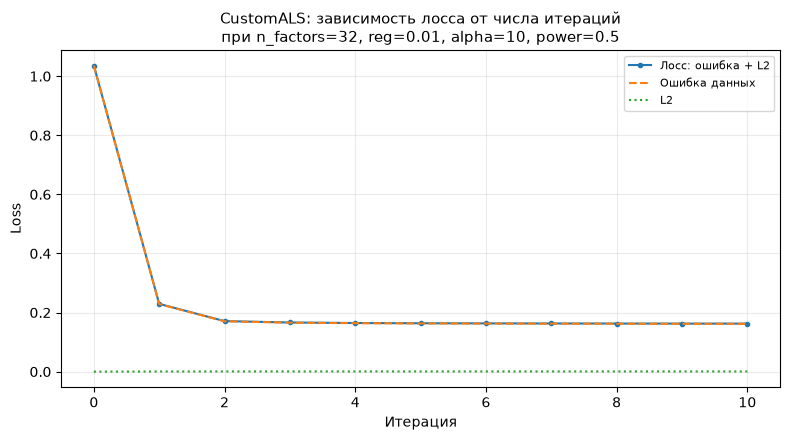

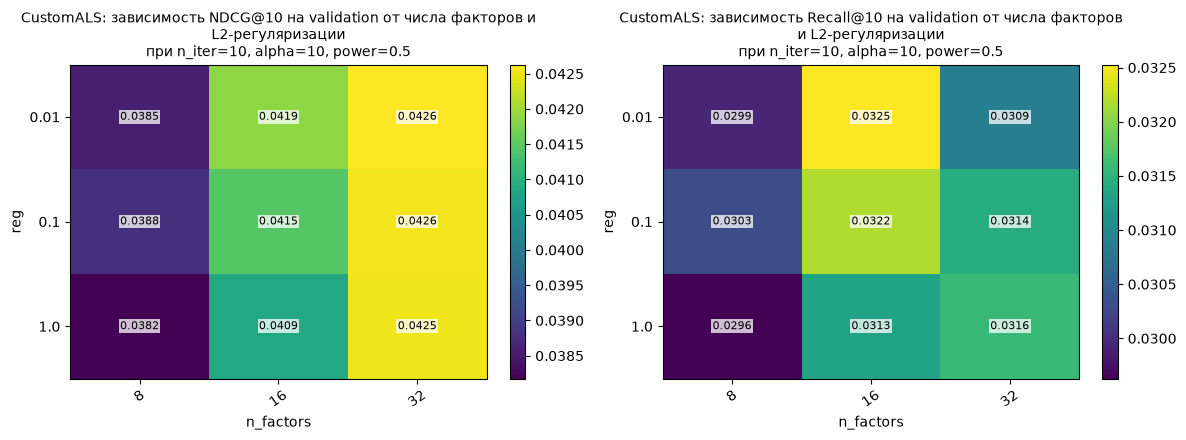

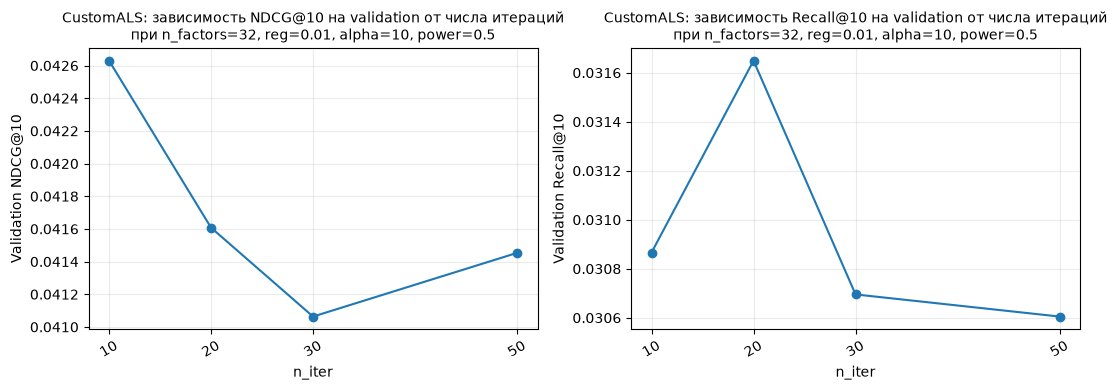

In [17]:
plot_loss_history(best_models['CustomALS'], 'CustomALS')
plot_search_heatmap(search_results['CustomALS'], best_parameters['CustomALS'], 'CustomALS', 'reg', 'n_factors')
plot_parameter_curve(search_results['CustomALS'], best_parameters['CustomALS'], 'CustomALS', 'n_iter')

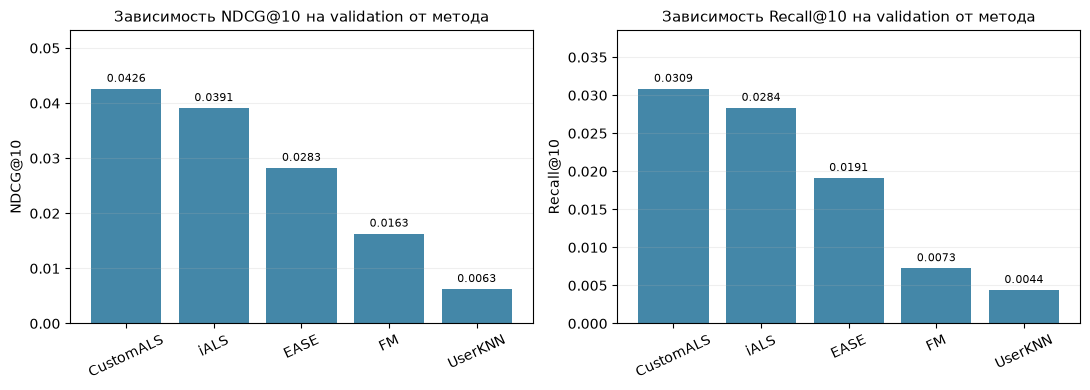

In [18]:
validation_summary = pd.DataFrame([
    {'model': name, **table.loc[table['NDCG@10'].idxmax(), ['NDCG@10', 'Recall@10']].to_dict()}
    for name, table in search_results.items()
])
plot_model_comparison(validation_summary, 'validation')

## 5. Финальное сравнение на test

1. Основная тестовая выборка — взаимодействия из big_matrix после второй временной границы $t>t_2$.
2. Используются только пользователи и видео, встречавшиеся в train выборке, чтобы не возникло проблемы холодного старта
3. Общая релевантность для всех моделей определяется по условию: watch_ratio >= 0.8.
4. Для оценки используются best_models, best_parameters и search_results, полученные выше при подборе гиперпараметров. 

In [20]:
from datetime import datetime, timezone

test_history = pd.concat([train_df, val_df], ignore_index=True)
test_truth = eligible_truth(test_df, test_history, users, items, RELEVANCE_THRESHOLD)
small_test_truth = eligible_truth(small_test_df, test_history, users, items, RELEVANCE_THRESHOLD)
assert not test_truth.empty, 'Нет доступных релевантных объектов test'
assert set(test_truth.user_id).issubset(set(train_df.user_id))
assert set(test_truth.video_id).issubset(set(train_df.video_id))
assert test_df.timestamp.min() > t2
measurement_time = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')
print('Замер выполнен:', measurement_time)
test_sizes = pd.DataFrame([
    {'Источник test': 'big_matrix', 'Взаимодействия после warm-start': len(test_df),
     'Релевантные пары': len(test_truth), 'Пользователи оценки': test_truth.user_id.nunique()},
    {'Источник test': 'small_matrix', 'Взаимодействия после warm-start': len(small_test_df),
     'Релевантные пары': len(small_test_truth), 'Пользователи оценки': small_test_truth.user_id.nunique()}
])
display(test_sizes)
test_users = test_truth.user_id.unique()
rows, small_rows = [], []
for name, model in best_models.items():
    pred = model.recommend(test_users, n=10, exclude=val_df)
    hits = len(pred.merge(test_truth[['user_id', 'video_id']], on=['user_id', 'video_id']))
    rows.append({'model': name, **ranking_metrics(pred, test_truth),
                 'hits@10': hits, 'best_parameters': best_parameters[name]})
    small_pred = model.recommend(small_test_truth.user_id.unique(), n=10, exclude=val_df)
    small_hits = len(small_pred.merge(small_test_truth[['user_id', 'video_id']], on=['user_id', 'video_id']))
    small_rows.append({'model': name, **ranking_metrics(small_pred, small_test_truth),
                       'hits@10': small_hits, 'best_parameters': best_parameters[name]})
final_results = pd.DataFrame(rows).sort_values('NDCG@10', ascending=False)
small_test_results = pd.DataFrame(small_rows).sort_values('NDCG@10', ascending=False)
print('Основной временной test: big_matrix')
display(final_results)

controlled_results = pd.DataFrame([
    {'model': 'binary target', **ranking_metrics(
        best_models['iALS'].recommend(test_users, exclude=val_df), test_truth)},
    {'model': 'continuous target, same ALS parameters', **ranking_metrics(
        matched_custom.recommend(test_users, exclude=val_df), test_truth)}])
display(controlled_results)
print('Дополнительная проверка переноса: small_matrix')
display(small_test_results)

Замер выполнен: 2026-10-30 19:42:14 UTC


,Источник test,Взаимодействия после warm-start,Релевантные пары,Пользователи оценки
0,big_matrix,48141,11897,1803
1,small_matrix,902,296,189


Основной временной test: big_matrix


,model,Recall@10,NDCG@10,n_users,hits@10,best_parameters
1,iALS,0.018994,0.017938,1803,213,"{'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'a..."
4,CustomALS,0.012757,0.010869,1803,125,"{'n_factors': 32, 'reg': 0.01, 'n_iter': 10, '..."
2,EASE,0.008638,0.007427,1803,111,{'reg': 3000.0}
0,UserKNN,0.002939,0.002842,1803,31,"{'similarity': 'cosine', 'k': 5}"
3,FM,0.000101,0.000258,1803,6,"{'n_factors': 32, 'reg': 0.001, 'learning_rate..."


,model,Recall@10,NDCG@10,n_users
0,binary target,0.018994,0.017938,1803
1,"continuous target, same ALS parameters",0.012689,0.010988,1803


Дополнительная проверка переноса: small_matrix


,model,Recall@10,NDCG@10,n_users,hits@10,best_parameters
0,UserKNN,0.0,0.0,189,0,"{'similarity': 'cosine', 'k': 5}"
1,iALS,0.0,0.0,189,0,"{'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'a..."
2,EASE,0.0,0.0,189,0,{'reg': 3000.0}
3,FM,0.0,0.0,189,0,"{'n_factors': 32, 'reg': 0.001, 'learning_rate..."
4,CustomALS,0.0,0.0,189,0,"{'n_factors': 32, 'reg': 0.01, 'n_iter': 10, '..."


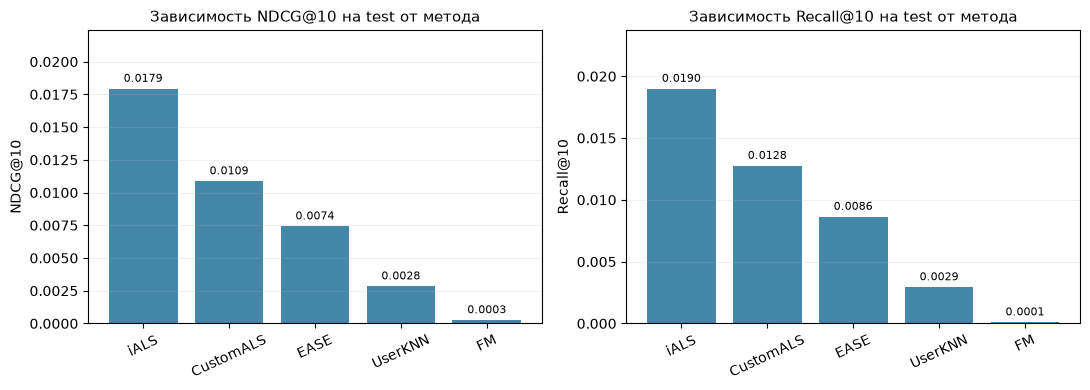

In [21]:
plot_model_comparison(final_results, 'test')

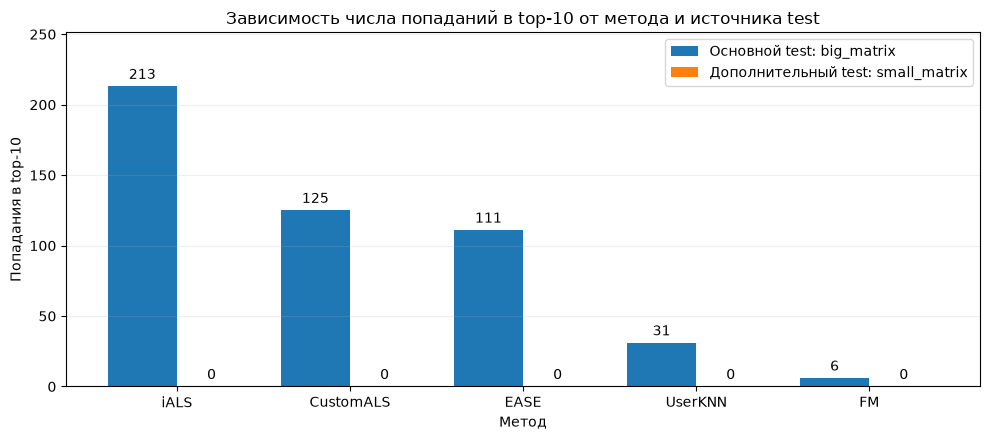

In [22]:
import matplotlib.pyplot as plt

order = final_results['model'].tolist()
main_hits = final_results.set_index('model').reindex(order)['hits@10']
small_hits = small_test_results.set_index('model').reindex(order)['hits@10']
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(10, 4.5))
a = ax.bar(x - 0.2, main_hits, width=0.4, label='Основной test: big_matrix')
b = ax.bar(x + 0.2, small_hits, width=0.4, label='Дополнительный test: small_matrix')
ax.bar_label(a, padding=3)
ax.bar_label(b, padding=3)
ax.set_xticks(x, order)
ax.set_xlabel('Метод')
ax.set_ylabel('Попадания в top-10')
ax.set_title('Зависимость числа попаданий в top-10 от метода и источника test')
ax.set_ylim(0, max(1, main_hits.max()) * 1.18)
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

### Общая таблица метрик и выбранных гиперпараметров

Настройки выбраны по validation NDCG@10 до финальной оценки. Показаны обе метрики
на validation и test и полный набор выбранных параметров.
Фиксированный batch_size FM — 2048.

In [23]:
validation_metrics = pd.DataFrame([
    {'model': name, **table.loc[table['NDCG@10'].idxmax(), ['NDCG@10', 'Recall@10']].to_dict()}
    for name, table in search_results.items()
]).rename(columns={'NDCG@10': 'Validation NDCG@10', 'Recall@10': 'Validation Recall@10'})
summary_results = final_results.rename(columns={
    'NDCG@10': 'Test NDCG@10', 'Recall@10': 'Test Recall@10'
}).merge(validation_metrics, on='model', validate='one_to_one')
summary_columns = ['model', 'Validation NDCG@10', 'Validation Recall@10',
                   'Test NDCG@10', 'Test Recall@10', 'best_parameters']
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(summary_results[summary_columns])

,model,Validation NDCG@10,Validation Recall@10,Test NDCG@10,Test Recall@10,best_parameters
0,iALS,0.039136,0.028367,0.017938,0.018994,"{'n_factors': 8, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'random_state': 42}"
1,CustomALS,0.042630,0.030866,0.010869,0.012757,"{'n_factors': 32, 'reg': 0.01, 'n_iter': 10, 'alpha': 10.0, 'power': 0.5, 'random_state': 42}"
2,EASE,0.028274,0.019149,0.007427,0.008638,{'reg': 3000.0}
3,UserKNN,0.006277,0.004418,0.002842,0.002939,"{'similarity': 'cosine', 'k': 5}"
4,FM,0.016328,0.007281,0.000258,0.000101,"{'n_factors': 32, 'reg': 0.001, 'learning_rate': 0.001, 'n_iter': 10, 'random_state': 42}"


## 6. Выводы и ограничения

Среди пяти моделей на основном тесте лучше всего сработала **iALS**:
NDCG@10 = 0,01794, Recall@10 = 0,01899 при 8 факторах, регуляризации 0,01
и 10 итерациях. На validation лидировала CustomALS, но её преимущество
не перенеслось на тест. При одинаковых параметрах ALS собственный целевой
сигнал также не дал улучшения.

Чтобы оценить масштаб метрик, после основного эксперимента дополнительно
проверили случайные рекомендации и популярность видео за последние 7 дней
train. Они используют те же кандидаты и правила исключения просмотренного.
Для случайного метода приведено точное математическое ожидание метрик.
Эта диагностика не использовалась при подборе параметров пяти моделей.

| Метод | Validation NDCG@10 | Test NDCG@10 |
|---|---:|---:|
| Случайные рекомендации — ожидаемое значение | 0,00645 | 0,00345 |
| Популярность за последние 7 дней train | 0,02708 | 0,02044 |
| iALS | 0,03914 | 0,01794 |
| CustomALS | 0,04263 | 0,01087 |
| EASE | 0,02827 | 0,00743 |
| UserKNN | 0,00628 | 0,00284 |
| FM | 0,01633 | 0,00026 |

**Свежесть данных важна.** Популярность за последние 7 дней train обошла
лучшую iALS на тесте примерно на 14% по NDCG@10. Между концом train и началом
теста прошло 20,46 дня, модели в этот период не обновлялись. Результат
поддерживает предположение об изменении интересов и популярности видео,
но не измеряет отдельно влияние самого временного разрыва.

**Малые значения метрик отчасти связаны с неполнотой оценки.** На тесте
у пользователя в среднем 2633 кандидата и только 6,6 известных релевантных
видео. Для 99,4% доступных пар в этом периоде нет наблюдений. Рекомендация
такого видео не даёт попадания, хотя мы не знаем, понравилось бы оно
пользователю. Поэтому абсолютные числа стоит сравнивать с базовыми методами:
iALS на тесте лучше случайного уровня примерно в 5,2 раза, CustomALS
на validation — в 6,6 раза. Влияние политики показов на оценку обсуждают
и [авторы KuaiRec](https://arxiv.org/html/2202.10842#S1).

**FM и UserKNN плохо переносятся на тест.** Обе модели оказались ниже
случайного уровня. Около 86% рекомендаций UserKNN и 71% рекомендаций FM —
видео, которые вообще не встречаются в тестовом периоде ни у одного
пользователя. Есть и вопросы к обучению: FM минимизирует MSE только
на наблюдавшихся парах, без отрицательных примеров из непоказанных видео;
UserKNN усредняет watch_ratio с выбросами вплоть до 158,6. Это возможные
причины слабого ранжирования, их вклад нужно проверять отдельно.
Без запуска FM без категорий также нельзя оценить пользу самих метаданных.

**Ограничения.** Сравнение проведено на случайной подвыборке, только для
известных пользователей и видео. Порог watch_ratio = 0,8 — условный признак
интереса; дубликаты могли повлиять на среднее, а категории считались
неизменными. На дополнительном small_matrix-тесте все модели получили нули;
после фильтрации в нём осталось 189 пользователей. Основной протокол
уточнялся после анализа этой оценки, поэтому для независимой проверки
нужен новый временной отрезок.

Единственная причина низких метрик пока не установлена. Проверки показывают
важность свежести данных, неполноту оценки и особенно слабый перенос
FM и UserKNN. Объяснять всё сложностью промышленной системы по этим данным
нельзя.
